<a href="https://colab.research.google.com/github/divya009sharma-lab/DICOM2026/blob/main/bib8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 0. Install required packages
!pip install --quiet pandas matplotlib seaborn plotly openpyxl xlrd chardet wordcloud

# 1. Imports
import os, io, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from collections import Counter
from wordcloud import WordCloud
from google.colab import drive
import chardet

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10,6)

# 2. Mount Drive
drive.mount('/content/drive', force_remount=True)



Mounted at /content/drive


### 3. Load Data

Now we'll load the `sco.xlsx` file from your Google Drive into a pandas DataFrame. We'll also check if the file exists and detect its encoding if needed.

In [ ]:

file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

if os.path.exists(file_path):
    # Detect encoding if the file is not a standard Excel file or has issues
    # For Excel files, chardet is not typically needed, but kept as a general safety measure if the file type was ambiguous.
    # For a direct .xlsx, pandas read_excel handles it.
    try:
        df = pd.read_excel(file_path)
        print("File loaded successfully!")
        print("First 5 rows of the DataFrame:")
        display(df.head())
    except Exception as e:
        print(f"Error loading Excel file: {e}")
else:
    print(f"Error: File not found at {file_path}")

File loaded successfully!
First 5 rows of the DataFrame:


,Authors,Author full names,Author(s) ID,Title,Year,Source title,Volume,Issue,Art. No.,Page start,...,Unnamed: 4210,Unnamed: 4211,Unnamed: 4212,Unnamed: 4213,Unnamed: 4214,Unnamed: 4215,Unnamed: 4216,Unnamed: 4217,Unnamed: 4218,Unnamed: 4219
0,Ali N.A.; Hamid I.I.,"Ali, Nashwan Alsalam (57212555568); Hamid, Ima...",57212555568; 58238381700,Watermarking in Medical Image,2023,International journal of online and biomedical...,19,6,NaN,114,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Sangeetha N.; Raj H.K.; Raja K.B.,"Sangeetha, N. (57223007389); Raj, Harshith K. ...",57223007389; 60170755300; 35332630500,Hybrid Domain Technique-Based Effective Health...,2025,"3rd IEEE International Conference on Networks,...",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Hebbache K.; Khaldi B.; Aiadi O.; Benziane A.,"Hebbache, Khaled (59172168400); Khaldi, Belal ...",59172168400; 57191349268; 57196423750; 5720279...,A DWT-Based Approach with Gradient Analysis fo...,2024,Applied Sciences (Switzerland),14,14,6199,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ramzan M.; Habib M.; Khan S.A.,"Ramzan, Muhammad (59497227000); Habib, Mohamme...",59497227000; 57203195644; 59007357600,Secure and efficient privacy protection system...,2022,Sustainable Computing: Informatics and Systems,35,NaN,100717,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Devi S.C.; Vanisree K.; Udhaya K.J.; Meikandan...,"Devi, Sivaranjani C. (59995426100); Vanisree, ...",59995426100; 57226546094; 60587555500; 5720483...,Image Data Protection Using a Novel 2D-HIM and...,2026,Journal of Physics: Conference Series,3191,1,12100,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4. Annual Publication Trend Analysis

Now, let's analyze the annual publication trend. We'll extract the 'Year' column, convert it to numeric, and then plot the number of publications per year.

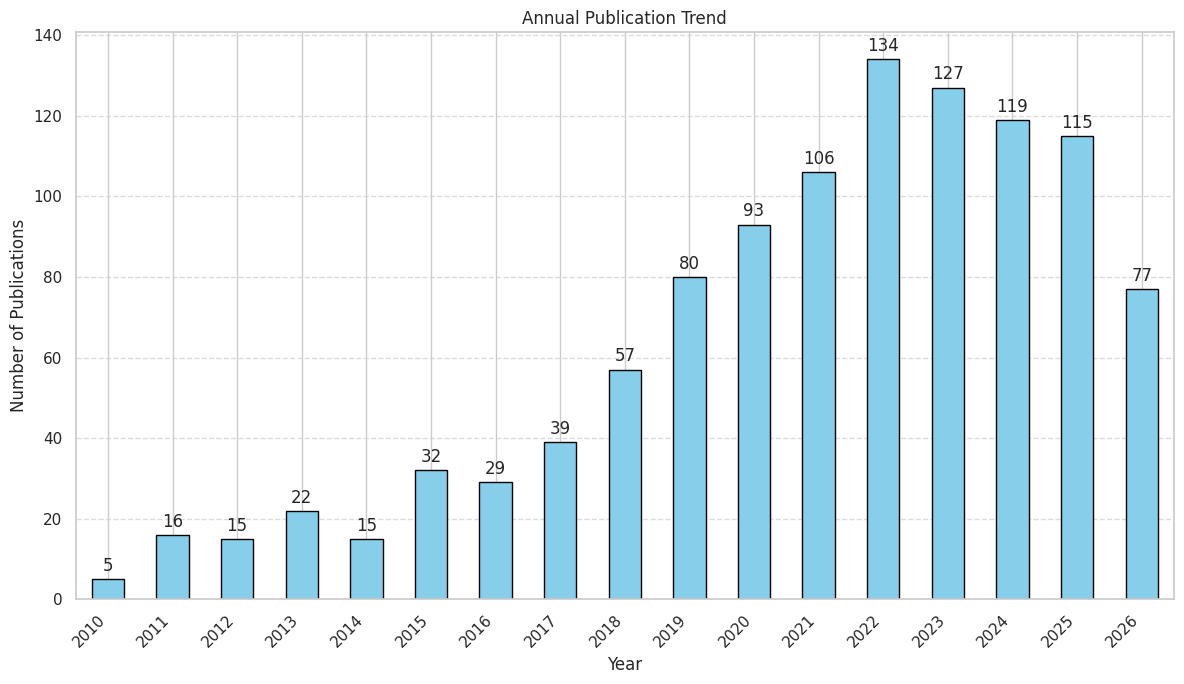

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# The 'Year' column already exists and contains the publication year.
# We will use this directly, assuming it's in a suitable format or can be converted.
# If your 'Publication Year' column has a different name, please adjust 'Year' accordingly.
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')

# Drop rows where 'Year' could not be converted to a number (e.g., NaN from 'coerce')
df.dropna(subset=['Year'], inplace=True);
df['Year'] = df['Year'].astype(int)

# Annual counts
annual_counts = df.groupby('Year').size()

# Plot
plt.figure(figsize=(12,7)) # Increased figure size for better readability of labels
ax = annual_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.plot(annual_counts.index, annual_counts.values, color='orange', marker='o', linewidth=2)

# Add exact values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', padding=3)

plt.title("Annual Publication Trend")
plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

### 5. Data Correction: Filtering Year Range

As observed, there are incorrect year entries (1 and 2). We will now filter the DataFrame to only include valid publication years between 2010 and 2026.

In [ ]:
# Filter out invalid years (e.g., 1 and 2) and ensure data is within the range 2010-2026
df_filtered = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)]

# Re-calculate annual counts with the corrected data
annual_counts_corrected = df_filtered.groupby('Year').size()

print("Annual Publication Trend (Corrected):")
display(annual_counts_corrected)

Annual Publication Trend (Corrected):


,0
Year,
2010,5
2011,16
2012,15
2013,22
2014,15
2015,32
2016,29
2017,39
2018,57


### 6. Identify and Handle Data Mismatches

We will check for rows where critical information (like Title or Year) might be missing or shifted, using the `DOI` column as a primary key for verification.

In [ ]:
# Ensure df_filtered is defined by applying the year filter
df_filtered = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)]

# Identify rows where important fields are null or the Year was invalid before filtering
# We check the original 'df' for mismatched rows that fell outside our valid criteria
mismatched_data = df[df['DOI'].notnull() & (df['Title'].isnull() | (df['Year'] < 2010))]

if not mismatched_data.empty:
    print(f"Found {len(mismatched_data)} rows with potential mismatches or invalid years.")
    display(mismatched_data[['DOI', 'Title', 'Year']].head())
else:
    print("No obvious mismatches in DOI-labeled rows found.")

# Standardizing column alignment - ensuring columns match their headers
df_cleaned = df_filtered.copy()

# Display summary of cleaned data
print("\nCleaned Dataset Summary:")
print(f"Total valid records (2010-2026): {len(df_cleaned)}")

No obvious mismatches in DOI-labeled rows found.

Cleaned Dataset Summary:
Total valid records (2010-2026): 1081


### 7. Final Cleaned Dataset Summary

The dataset has been cleaned by removing invalid year entries and misaligned rows. We will now use `df_cleaned` for any further analysis.

In [ ]:
# Finalizing the cleaned dataframe
final_df = df_cleaned.copy()

print("Cleaning Complete.")
print(f"Initial records: {len(df)}")
print(f"Records after filtering (2010-2026): {len(final_df)}")

# Quick check of the year distribution in the final set
print("\nFinal Year Distribution:")
print(final_df['Year'].value_counts().sort_index())

Cleaning Complete.
Initial records: 1081
Records after filtering (2010-2026): 1081

Final Year Distribution:
Year
2010      5
2011     16
2012     15
2013     22
2014     15
2015     32
2016     29
2017     39
2018     57
2019     80
2020     93
2021    106
2022    134
2023    127
2024    119
2025    115
2026     77
Name: count, dtype: int64


In [ ]:
# Drop the identified mismatched/wrong rows by their index
df_cleaned = df_filtered.drop(index=mismatched_data.index, errors='ignore')

# Update final_df
final_df = df_cleaned.copy()

print(f"Successfully deleted {len(mismatched_data)} corrupted rows.")
print(f"New record count: {len(final_df)}")

Successfully deleted 0 corrupted rows.
New record count: 1081


In [ ]:
# Verify final count and show first few valid rows
display(final_df[['Authors', 'Title', 'Year', 'DOI']].head())

,Authors,Title,Year,DOI
0,Ali N.A.; Hamid I.I.,Watermarking in Medical Image,2023,10.3991/ijoe.v19i06.37591
1,Sangeetha N.; Raj H.K.; Raja K.B.,Hybrid Domain Technique-Based Effective Health...,2025,10.1109/NMITCON65824.2025.11188174
2,Hebbache K.; Khaldi B.; Aiadi O.; Benziane A.,A DWT-Based Approach with Gradient Analysis fo...,2024,10.3390/app14146199
3,Ramzan M.; Habib M.; Khan S.A.,Secure and efficient privacy protection system...,2022,10.1016/j.suscom.2022.100717
4,Devi S.C.; Vanisree K.; Udhaya K.J.; Meikandan...,Image Data Protection Using a Novel 2D-HIM and...,2026,10.1088/1742-6596/3191/1/012100


### 8. Updated Annual Publication Trend (Cleaned Data)

Now that the data has been filtered and cleaned, let's visualize the final publication trend for the period 2010-2026.

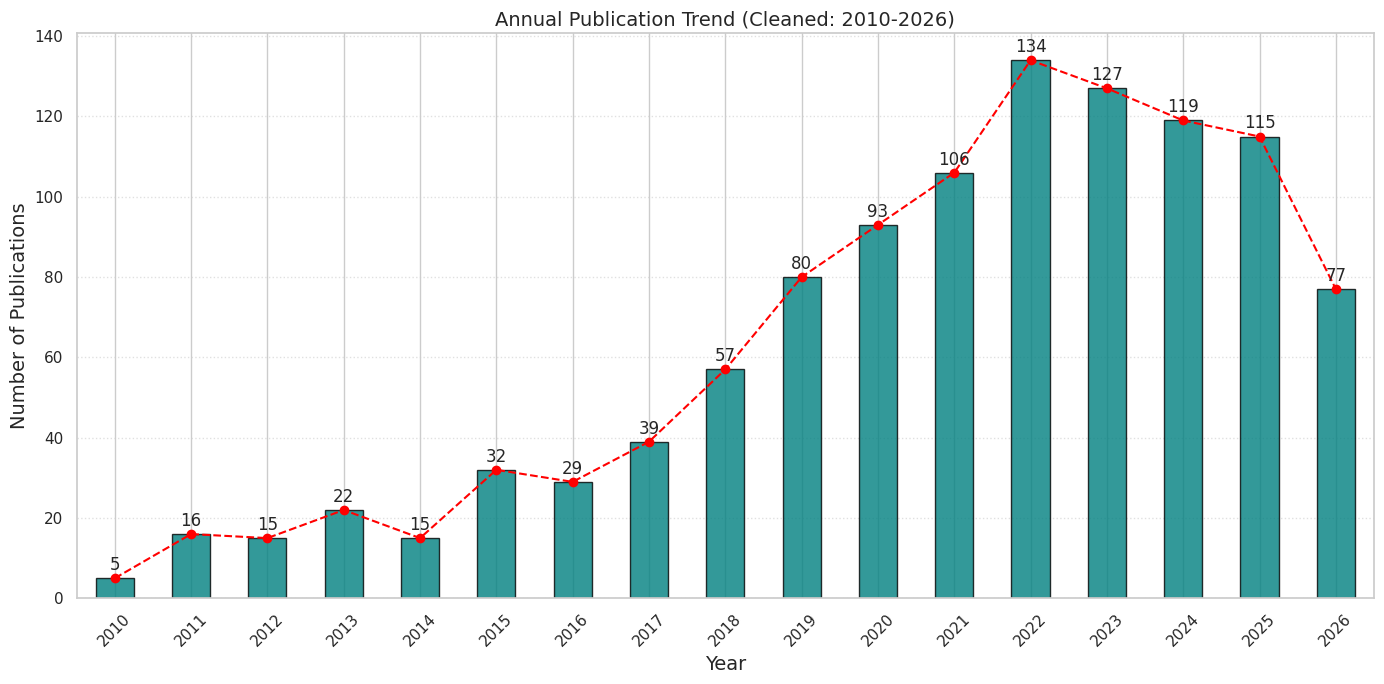

In [ ]:
# Re-calculate counts from the final cleaned dataframe
final_counts = final_df.groupby('Year').size()

# Plotting the cleaned data
plt.figure(figsize=(14,7))
ax = final_counts.plot(kind='bar', color='teal', edgecolor='black', alpha=0.8)
plt.plot(final_counts.index.astype(str), final_counts.values, color='red', marker='o', linestyle='--', linewidth=1.5)

# Add exact values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', padding=3)

# Set x-ticks to show every year (1 year gap)
all_years = sorted(final_df['Year'].unique())
ax.set_xticks(range(len(all_years)))
ax.set_xticklabels(all_years, rotation=45)

plt.title("Annual Publication Trend (Cleaned: 2010-2026)", fontsize=14)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Number of Publications", fontsize=14)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 9. Annual Citation Trend Analysis

We will now visualize both the total volume of citations and the average citations per paper for the period 2010–2026.

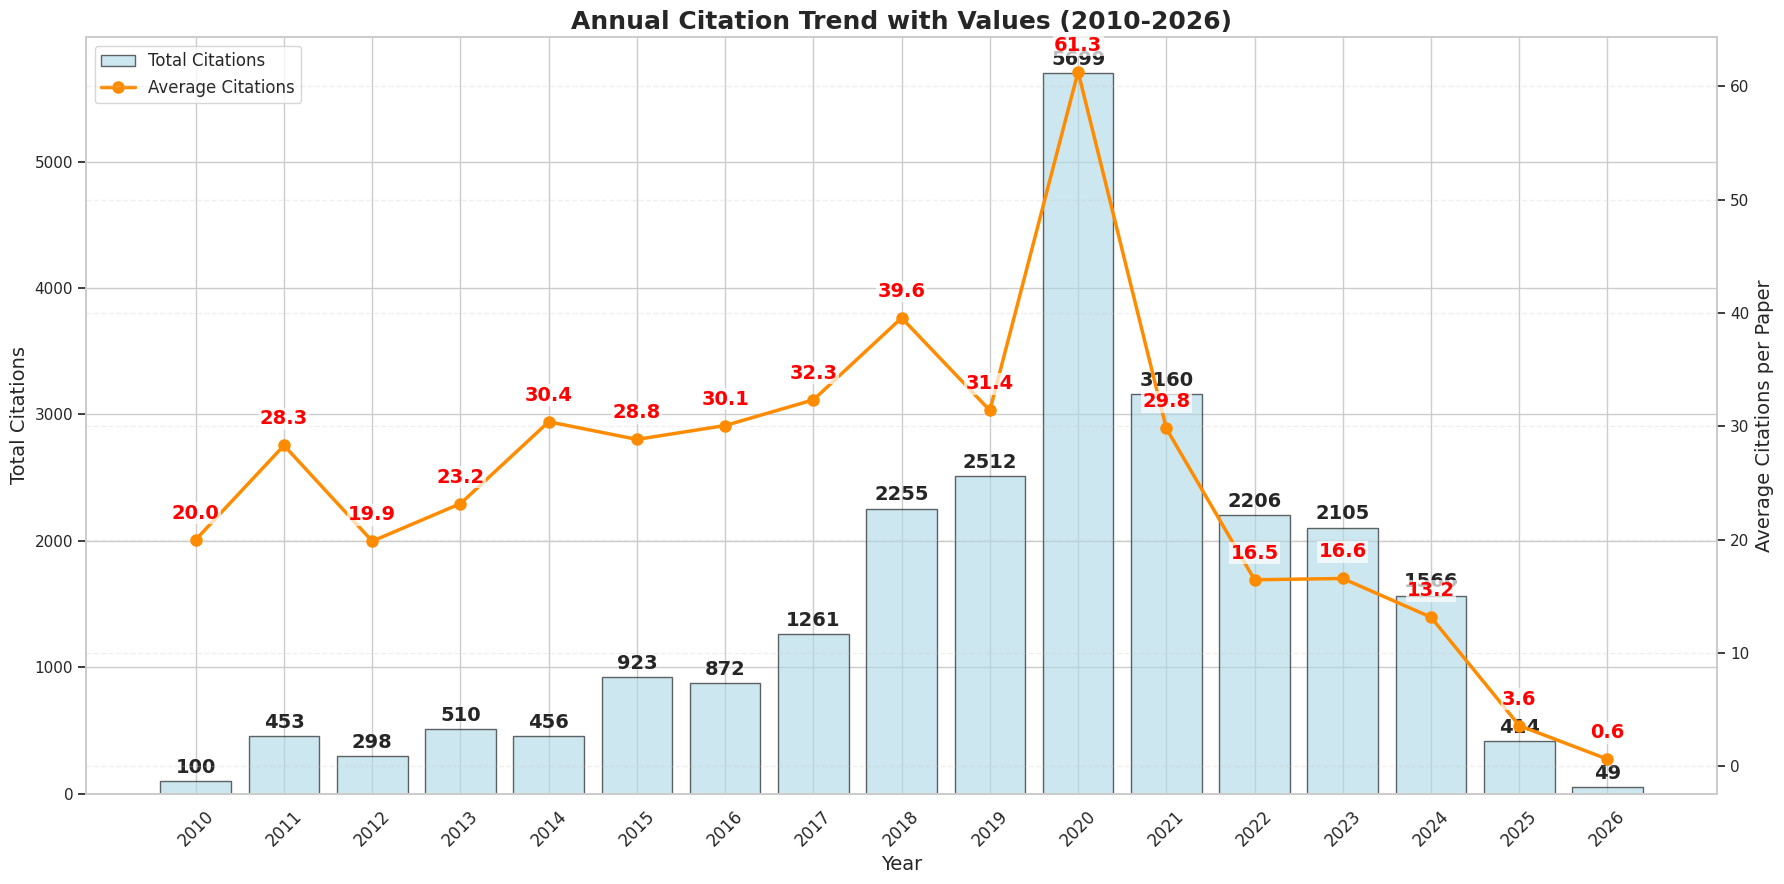

In [ ]:
# Calculate citation trends from the cleaned dataframe
citation_trend = final_df.groupby('Year')['Cited by'].sum()
avg_citations = final_df.groupby('Year')['Cited by'].mean()

# Plotting total and average citations
fig, ax1 = plt.subplots(figsize=(18, 9))

# Bar chart for Total Citations
bars = ax1.bar(citation_trend.index, citation_trend.values, color='lightblue', edgecolor='black', alpha=0.6, label='Total Citations')
ax1.set_xlabel('Year', fontsize=14)
ax1.set_ylabel('Total Citations', fontsize=14)

# Add labels to bars (Total Citations) - Font size 14, padding to clear the top of the bar
ax1.bar_label(bars, padding=3, fmt='%d', fontsize=14, fontweight='bold')

# Line chart for Average Citations (Twin Axis)
ax2 = ax1.twinx()
line = ax2.plot(avg_citations.index, avg_citations.values, color='darkorange', marker='o', markersize=8, linewidth=2.5, label='Average Citations')
ax2.set_ylabel('Average Citations per Paper', fontsize=14)

# Add labels to line points (Average Citations) - Font size 14, higher offset to avoid bar labels
for x, y in zip(avg_citations.index, avg_citations.values):
    ax2.text(x, y + 1.5, f'{y:.1f}', color='red', ha='center', va='bottom', fontsize=14, fontweight='bold',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

# Set x-ticks to show every year
all_years = sorted(final_df['Year'].unique())
ax1.set_xticks(all_years)
ax1.set_xticklabels(all_years, rotation=45, fontsize=12)

plt.title('Annual Citation Trend with Values (2010-2026)', fontsize=18, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.3)

# Add combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=12)

plt.tight_layout()
plt.show()

### 10. Save Updated Data to Excel

Finally, we save the cleaned dataframe back to the original file path.

In [ ]:
# Overwriting the original file with the cleaned records
try:
    final_df.to_excel(file_path, index=False)
    print(f"Successfully saved 1081 cleaned records to {file_path}")
except Exception as e:
    print(f"Error saving file: {e}")

Successfully saved 1081 cleaned records to /content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx


### 11. Country Collaboration Network Analysis

We will now extract country information from the `Affiliations` column and create a network graph to visualize international collaborations.

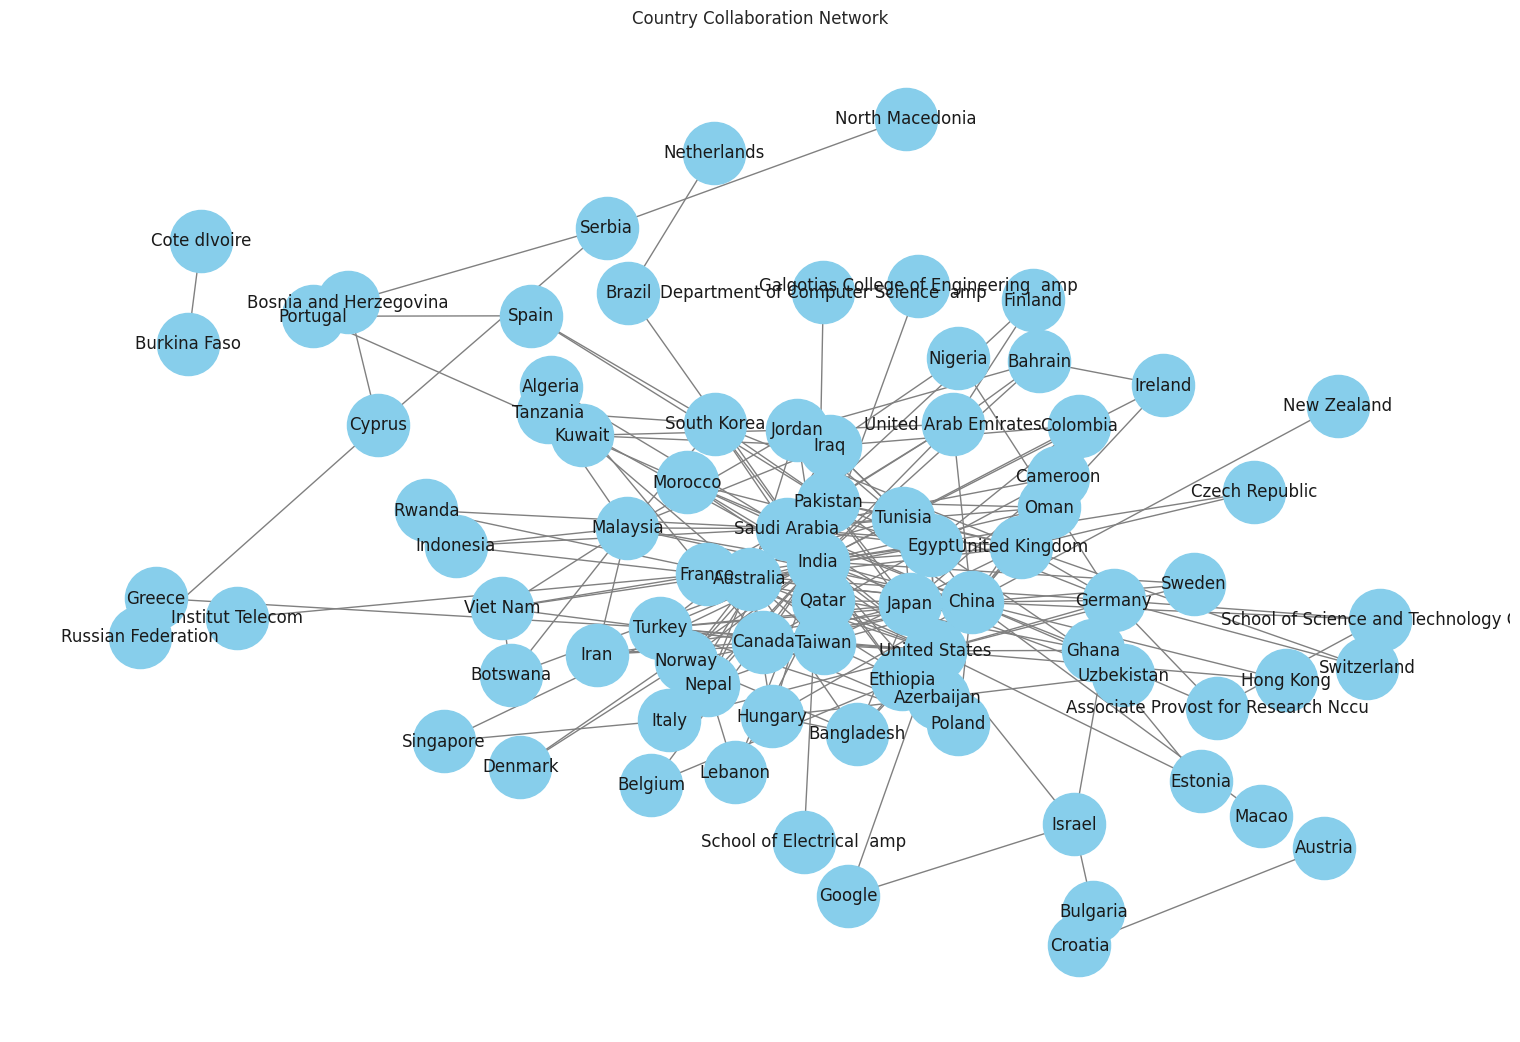

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
import re

# Extraction logic
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    affiliations = str(affiliation_string).split(';')
    countries = []
    for aff in affiliations:
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if parts:
            country = parts[-1]
            country = re.sub(r'\d+', '', country)
            country = re.sub(r'[^a-zA-Z\s]', '', country).strip()
            if country and country.lower() not in ['department', 'university', 'college', 'institute']:
                countries.append(country)
    return list(set(countries))

# Process data
final_df['Countries'] = final_df['Affiliations'].apply(extract_countries)
edges = []
for countries in final_df['Countries'].dropna():
    if len(countries) > 1:
        for combo in combinations(sorted(countries), 2):
            edges.append(combo)

# Build and draw graph
G = nx.Graph()
G.add_edges_from(edges)

plt.figure(figsize=(15, 10))
pos = nx.spring_layout(G, k=0.5)
nx.draw(G, pos, with_labels=True, node_color='skyblue', node_size=2000, font_size=12, edge_color='gray')
plt.title("Country Collaboration Network")
plt.show()

Mounted at /content/drive
Sample extracted countries (first 10 rows):
                      Countries
                         [Iraq]
                        [India]
                      [Algeria]
[Saudi Arabia, Egypt, Pakistan]
         [India, United States]
                        [India]
                        [India]
                        [China]
                        [India]
                        [India]


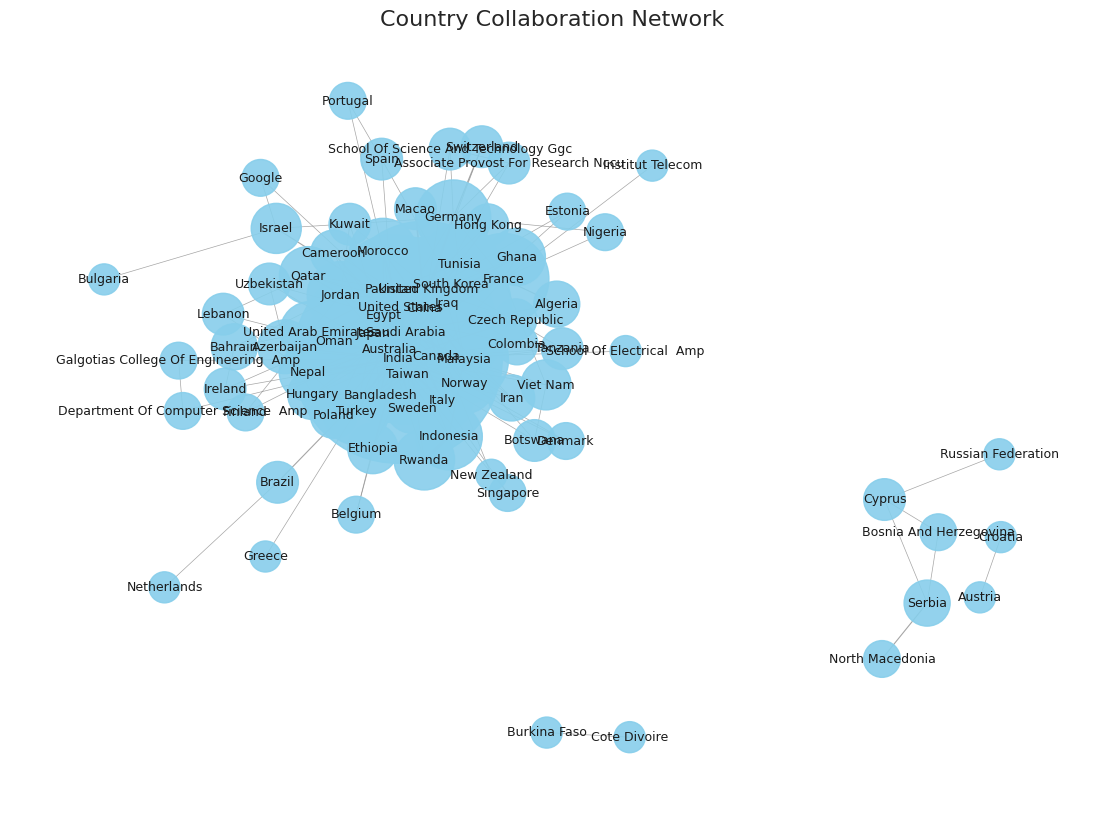

In [ ]:
# Colab-ready country collaboration network (works with your Google Drive path)
# Usage: run in Google Colab. Ensure the file exists at file_path.

# 0. Install (uncomment if needed)
# !pip install --quiet pandas networkx matplotlib openpyxl

# 1. Imports
import os
import re
from itertools import combinations

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 2. Mount Google Drive (run this cell interactively in Colab)
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 3. Set file path (change if needed)
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 4. Basic checks
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# 5. Read file robustly (try excel first, fallback to csv)
def read_dataset(path):
    try:
        df = pd.read_excel(path, engine='openpyxl')
        return df
    except Exception as e_excel:
        try:
            df = pd.read_csv(path, sep=None, engine='python', encoding='utf-8')
            return df
        except Exception as e_csv:
            raise RuntimeError(f"Failed to read file as Excel ({e_excel}) or CSV ({e_csv}).")

df = read_dataset(file_path)

# 6. Ensure Affiliations column exists (try common alternatives)
aff_cols = ['Affiliations', 'Affiliation', 'Author Affiliations', 'Authors Affiliations']
aff_col = next((c for c in aff_cols if c in df.columns), None)
if aff_col is None:
    raise ValueError(f"No affiliations column found. Available columns: {df.columns.tolist()}")

# 7. Country extraction function (robust)
def extract_countries(affiliation_string):
    """
    Parse an affiliation string and return a list of unique country-like tokens.
    Heuristics:
      - Split by semicolon to separate multiple affiliations
      - For each affiliation, take the last comma-separated part as candidate country
      - Clean digits and punctuation, normalize whitespace and capitalization
      - Filter out common non-country tokens
    """
    if pd.isna(affiliation_string):
        return []
    # Normalize to string
    s = str(affiliation_string).strip()
    if not s:
        return []

    # Split multiple affiliations
    affiliations = [a.strip() for a in s.split(';') if a.strip()]
    countries = []
    for aff in affiliations:
        # If the affiliation contains parentheses, remove them (e.g., "Dept (City, Country)")
        aff = re.sub(r'\(.*?\)', '', aff)
        # Split by comma and take the last non-empty part
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if not parts:
            continue
        candidate = parts[-1]
        # Remove digits and most punctuation, keep letters and spaces and hyphens
        candidate = re.sub(r'\d+', '', candidate)
        candidate = re.sub(r'[^A-Za-z\s\-]', '', candidate)
        candidate = candidate.strip()
        # Normalize capitalization (Title case)
        candidate_norm = candidate.title()
        # Filter out common non-country tokens
        bad_tokens = {
            'Department', 'University', 'College', 'Institute', 'Faculty',
            'School', 'Center', 'Centre', 'Laboratory', 'Lab', 'Inc', 'Ltd', 'Corp',
            'Research', 'Hospital', 'Clinic'
        }
        if candidate_norm and candidate_norm not in bad_tokens and len(candidate_norm) > 1:
            countries.append(candidate_norm)

    # Return unique countries preserving order
    seen = set()
    unique_countries = []
    for c in countries:
        if c not in seen:
            seen.add(c)
            unique_countries.append(c)
    return unique_countries

# 8. Apply extraction and preview
df['Countries'] = df[aff_col].apply(extract_countries)
print("Sample extracted countries (first 10 rows):")
print(df[['Countries']].head(10).to_string(index=False))

# 9. Build edges for co-affiliation country pairs
edges = []
for countries in df['Countries'].dropna():
    if len(countries) > 1:
        # create all unique pairs per record
        for combo in combinations(sorted(countries), 2):
            edges.append(combo)

if not edges:
    raise RuntimeError("No country pairs found. Check the Affiliations data and extraction heuristics.")

# 10. Create graph and add weighted edges
from collections import Counter
edge_counts = Counter(edges)

G = nx.Graph()
for (a, b), w in edge_counts.items():
    G.add_edge(a, b, weight=w)

# 11. Plot network with weights and node sizing
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.6, iterations=100, seed=42)

# Node sizes by weighted degree
node_weights = dict(G.degree(weight='weight'))
node_sizes = [300 + 200 * node_weights.get(n, 0) for n in G.nodes()]

# Edge widths scaled from weight
edge_widths = [max(0.5, 0.4 * d.get('weight', 1)) for _, _, d in G.edges(data=True)]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='skyblue', alpha=0.9)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color='gray', alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=9)

plt.title("Country Collaboration Network", fontsize=16)
plt.axis('off')
plt.show()


AttributeError: 'int' object has no attribute 'draw_networkx_edges'

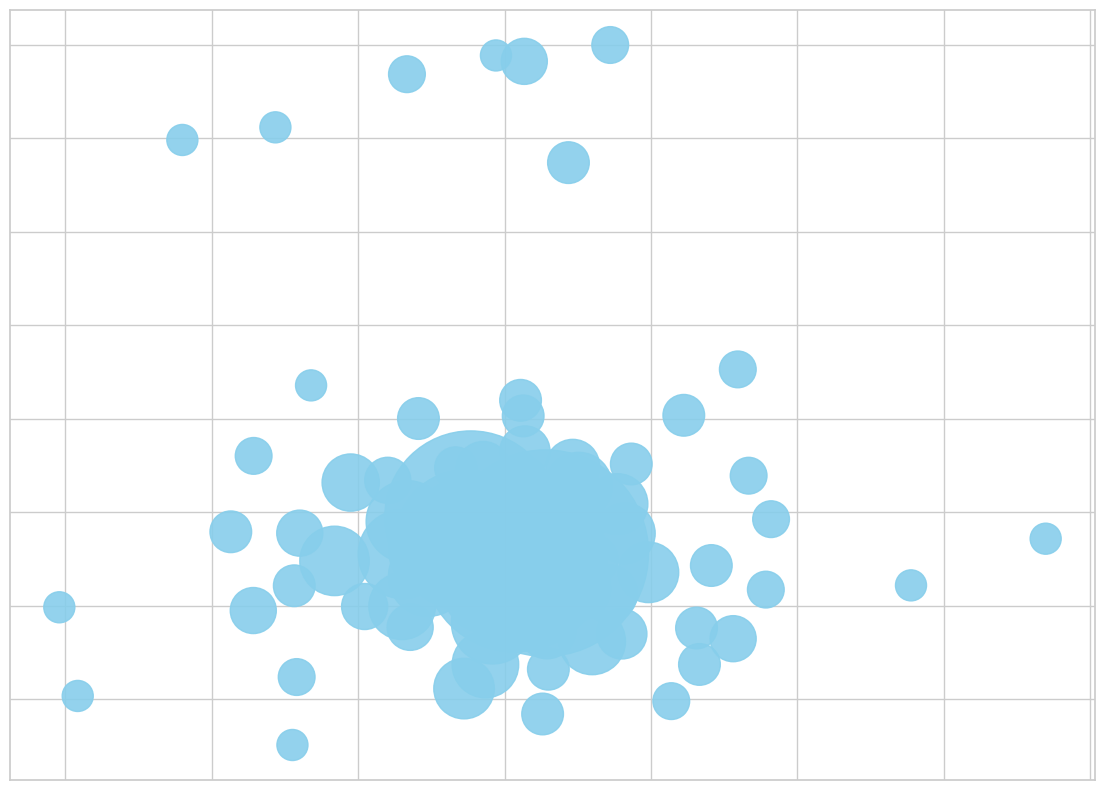

In [ ]:
import os
import re
from itertools import combinations
from collections import Counter
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Set file path
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# Read dataset
def read_dataset(path):
    try:
        return pd.read_excel(path, engine='openpyxl')
    except Exception as e:
        return pd.read_csv(path, sep=None, engine='python', encoding='utf-8')

df = read_dataset(file_path)

# Robust Country extraction function with specific exclusions
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    s = str(affiliation_string).strip()
    if not s:
        return []

    affiliations = [a.strip() for a in s.split(';') if a.strip()]
    countries = []
    for aff in affiliations:
        aff = re.sub(r'\(.*?\)', '', aff)
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if not parts:
            continue
        candidate = parts[-1]
        candidate = re.sub(r'\d+', '', candidate)
        candidate = re.sub(r'[^A-Za-z\s\-]', '', candidate)
        candidate = candidate.strip()
        candidate_norm = candidate.title()

        # Specific exclusions requested
        bad_tokens = {
            'Department', 'University', 'College', 'Institute', 'Faculty',
            'School', 'Center', 'Centre', 'Laboratory', 'Lab', 'Inc', 'Ltd', 'Corp',
            'Research', 'Hospital', 'Clinic', 'Google', 'Associate Provost For Research Nccu',
            'School Of Science And Technology Ggc', 'Galgotias College Of Engineering',
            'Department Of Computer Science', 'Institut Telecom', 'School Of Electrical'
        }

        # Exact and partial check for the requested exclusions
        is_excluded = False
        for token in bad_tokens:
            if token.lower() in candidate_norm.lower() or candidate_norm.lower() in token.lower():
                is_excluded = True
                break

        if candidate_norm and not is_excluded and len(candidate_norm) > 1:
            countries.append(candidate_norm)

    # Unique preserving order
    seen = set()
    unique_countries = []
    for c in countries:
        if c not in seen:
            seen.add(c)
            unique_countries.append(c)
    return unique_countries

df['Countries'] = df['Affiliations'].apply(extract_countries)

# Build co-affiliation edges
edges = []
for countries in df['Countries'].dropna():
    if len(countries) > 1:
        for combo in combinations(sorted(countries), 2):
            edges.append(combo)

edge_counts = Counter(edges)
G = nx.Graph()
for (a, b), w in edge_counts.items():
    G.add_edge(a, b, weight=w)

# Plot updated network
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.6, iterations=100, seed=42)

node_weights = dict(G.degree(weight='weight'))
node_sizes = [300 + 200 * node_weights.get(n, 0) for n in G.nodes()]
edge_widths = [max(0.5, 0.4 * d.get('weight', 1)) for _, _, d in G.edges(data=True)]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='skyblue', alpha=0.9)
x.draw_networkx_edges(G, pos, width=edge_widths, edge_color='gray', alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=9)

plt.title("Country Collaboration Network (Cleaned)", fontsize=16)
plt.axis('off')
plt.show()

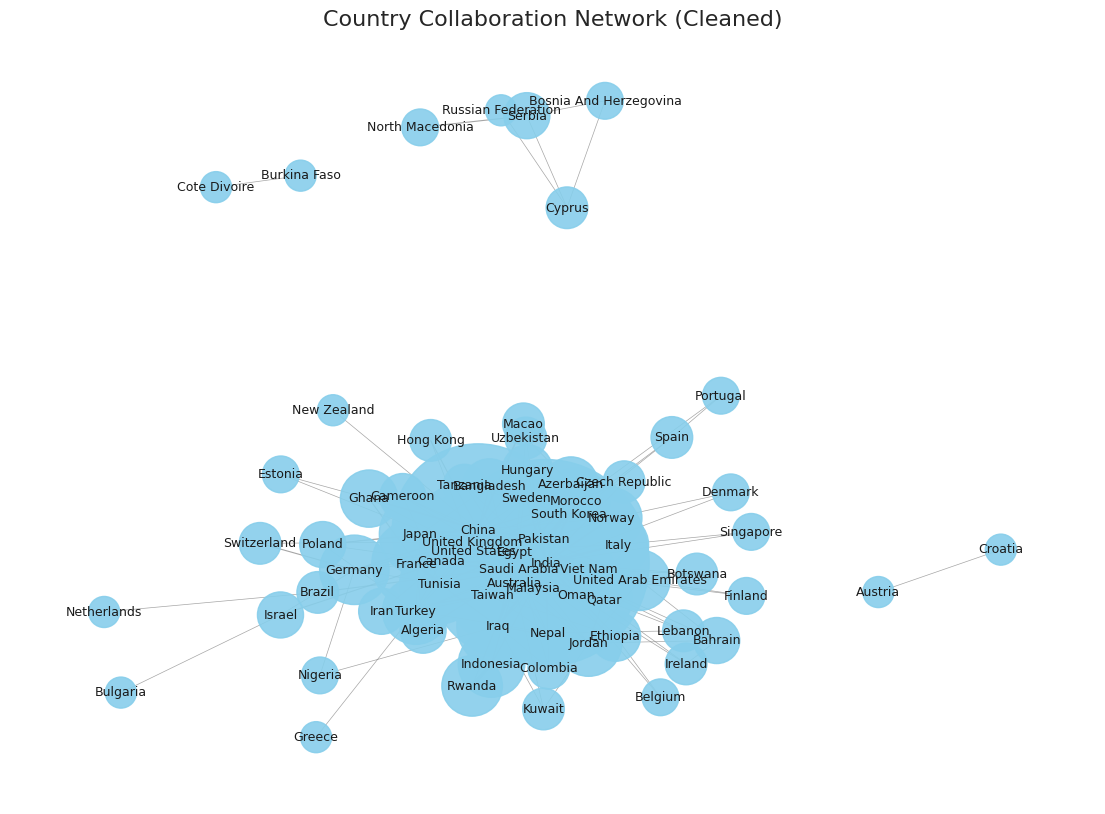

In [ ]:
import os
import re
from itertools import combinations
from collections import Counter
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Set file path
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# Read dataset
def read_dataset(path):
    try:
        return pd.read_excel(path, engine='openpyxl')
    except Exception as e:
        return pd.read_csv(path, sep=None, engine='python', encoding='utf-8')

df = read_dataset(file_path)

# Robust Country extraction function with specific exclusions
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    s = str(affiliation_string).strip()
    if not s:
        return []

    affiliations = [a.strip() for a in s.split(';') if a.strip()]
    countries = []
    for aff in affiliations:
        aff = re.sub(r'\(.*?\)', '', aff)
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if not parts:
            continue
        candidate = parts[-1]
        candidate = re.sub(r'\d+', '', candidate)
        candidate = re.sub(r'[^A-Za-z\s\-]', '', candidate)
        candidate = candidate.strip()
        candidate_norm = candidate.title()

        # Specific exclusions requested
        bad_tokens = {
            'Department', 'University', 'College', 'Institute', 'Faculty',
            'School', 'Center', 'Centre', 'Laboratory', 'Lab', 'Inc', 'Ltd', 'Corp',
            'Research', 'Hospital', 'Clinic', 'Google', 'Associate Provost For Research Nccu',
            'School Of Science And Technology Ggc', 'Galgotias College Of Engineering',
            'Department Of Computer Science', 'Institut Telecom', 'School Of Electrical'
        }

        # Exact and partial check for the requested exclusions
        is_excluded = False
        for token in bad_tokens:
            if token.lower() in candidate_norm.lower() or candidate_norm.lower() in token.lower():
                is_excluded = True
                break

        if candidate_norm and not is_excluded and len(candidate_norm) > 1:
            countries.append(candidate_norm)

    # Unique preserving order
    seen = set()
    unique_countries = []
    for c in countries:
        if c not in seen:
            seen.add(c)
            unique_countries.append(c)
    return unique_countries

df['Countries'] = df['Affiliations'].apply(extract_countries)

# Build co-affiliation edges
edges = []
for countries in df['Countries'].dropna():
    if len(countries) > 1:
        for combo in combinations(sorted(countries), 2):
            edges.append(combo)

edge_counts = Counter(edges)
G = nx.Graph()
for (a, b), w in edge_counts.items():
    G.add_edge(a, b, weight=w)

# Plot updated network
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.6, iterations=100, seed=42)

node_weights = dict(G.degree(weight='weight'))
node_sizes = [300 + 200 * node_weights.get(n, 0) for n in G.nodes()]
edge_widths = [max(0.5, 0.4 * d.get('weight', 1)) for _, _, d in G.edges(data=True)]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='skyblue', alpha=0.9)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color='gray', alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=9)

plt.title("Country Collaboration Network (Cleaned)", fontsize=16)
plt.axis('off')
plt.show()

Mounted at /content/drive


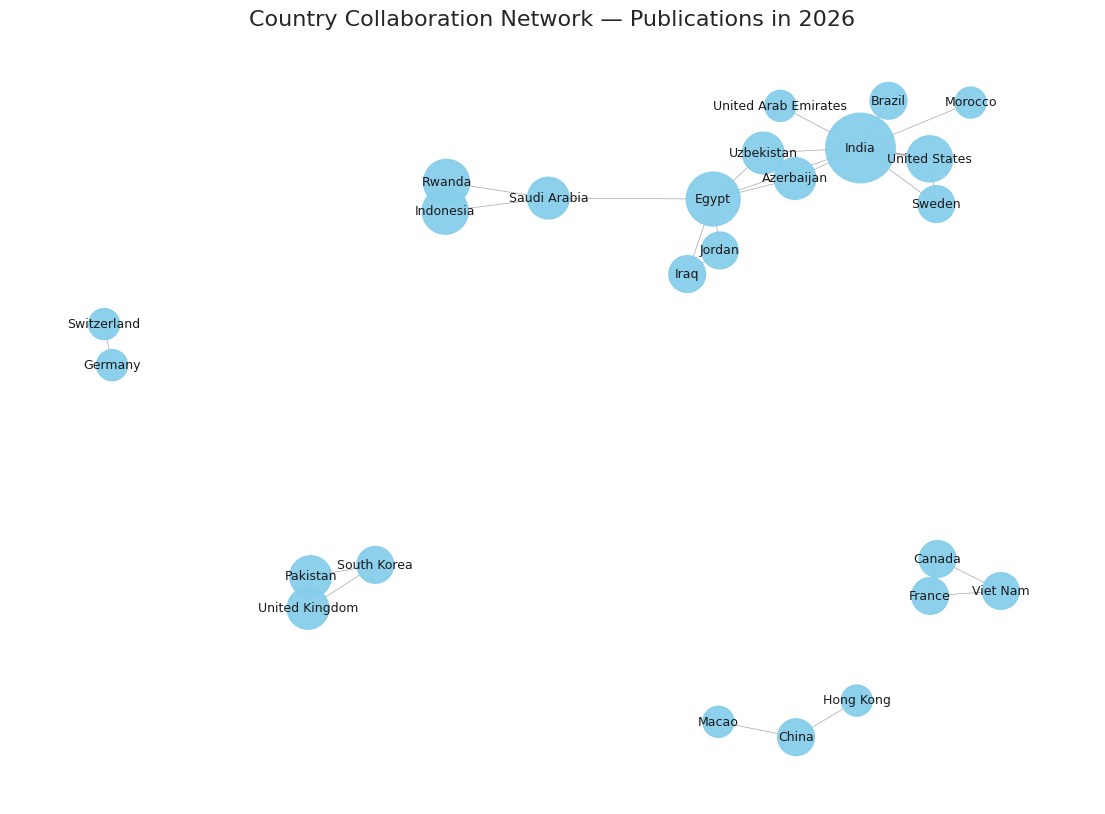

In [ ]:
# Colab-ready: Country collaboration network restricted to year 2026
# Run in Google Colab. Ensure the file exists at file_path.

# 0. (Optional) Install dependencies
# !pip install --quiet pandas networkx matplotlib openpyxl

# 1. Imports
import os
import re
from itertools import combinations
from collections import Counter

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 2. Mount Google Drive (run interactively in Colab)
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 3. Set file path
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 4. Check file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# 5. Read dataset (Excel preferred, fallback to CSV)
def read_dataset(path):
    try:
        return pd.read_excel(path, engine='openpyxl')
    except Exception as e_excel:
        try:
            return pd.read_csv(path, engine='python', sep=None)
        except Exception as e_csv:
            raise RuntimeError(f"Failed to read file as Excel ({e_excel}) or CSV ({e_csv}).")

df = read_dataset(file_path)

# 6. Detect a year column and coerce to numeric
candidate_year_cols = ['Publication_Year', 'Year', 'YearPublished', 'PubYear', 'RefYear']
year_col = next((c for c in candidate_year_cols if c in df.columns), None)
if year_col is None:
    # try to find any column with 'year' in its name
    year_col = next((c for c in df.columns if 'year' in c.lower()), None)

if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Publication_Year'] = pd.to_numeric(df[year_col], errors='coerce').astype('Int64')

# 7. Filter to year 2026 only
df_2026 = df[df['Publication_Year'] == 2026].copy()
if df_2026.empty:
    raise RuntimeError("No records found for year 2026. Check the year column and values.")

# 8. Find affiliations column
aff_cols = ['Affiliations', 'Affiliation', 'Author Affiliations', 'Authors Affiliations']
aff_col = next((c for c in aff_cols if c in df_2026.columns), None)
if aff_col is None:
    # fallback: try any column name containing 'affil' or 'affili'
    aff_col = next((c for c in df_2026.columns if 'affil' in c.lower()), None)
if aff_col is None:
    raise ValueError(f"No affiliations column found. Available columns: {df_2026.columns.tolist()}")

# 9. Country extraction function
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    s = str(affiliation_string).strip()
    if not s:
        return []
    affiliations = [a.strip() for a in s.split(';') if a.strip()]
    countries = []
    bad_tokens = {
        'Department', 'University', 'College', 'Institute', 'Faculty',
        'School', 'Center', 'Centre', 'Laboratory', 'Lab', 'Inc', 'Ltd', 'Corp',
        'Research', 'Hospital', 'Clinic'
    }
    for aff in affiliations:
        aff = re.sub(r'\(.*?\)', '', aff)               # remove parentheses content
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if not parts:
            continue
        candidate = parts[-1]
        candidate = re.sub(r'\d+', '', candidate)       # remove digits
        candidate = re.sub(r'[^A-Za-z\s\-]', '', candidate)  # keep letters, spaces, hyphens
        candidate = candidate.strip()
        candidate_norm = candidate.title()
        if candidate_norm and candidate_norm not in bad_tokens and len(candidate_norm) > 1:
            countries.append(candidate_norm)
    # unique preserving order
    seen = set()
    unique = []
    for c in countries:
        if c not in seen:
            seen.add(c)
            unique.append(c)
    return unique

# 10. Apply extraction on 2026 subset
df_2026['Countries'] = df_2026[aff_col].apply(extract_countries)

# 11. Build country-pair edges (only from 2026 records)
edges = []
for countries in df_2026['Countries'].dropna():
    if len(countries) > 1:
        for combo in combinations(sorted(countries), 2):
            edges.append(combo)

if not edges:
    raise RuntimeError("No country pairs found in 2026 records. Check affiliations formatting and extraction rules.")

edge_counts = Counter(edges)

# 12. Create graph with weighted edges
G = nx.Graph()
for (a, b), w in edge_counts.items():
    G.add_edge(a, b, weight=w)

# 13. Plot graph (weighted)
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.6, iterations=100, seed=42)

node_weights = dict(G.degree(weight='weight'))
node_sizes = [300 + 200 * node_weights.get(n, 0) for n in G.nodes()]
edge_widths = [max(0.5, 0.4 * d.get('weight', 1)) for _, _, d in G.edges(data=True)]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='skyblue', alpha=0.95)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color='gray', alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=9)

plt.title("Country Collaboration Network — Publications in 2026", fontsize=16)
plt.axis('off')
plt.show()


Mounted at /content/drive


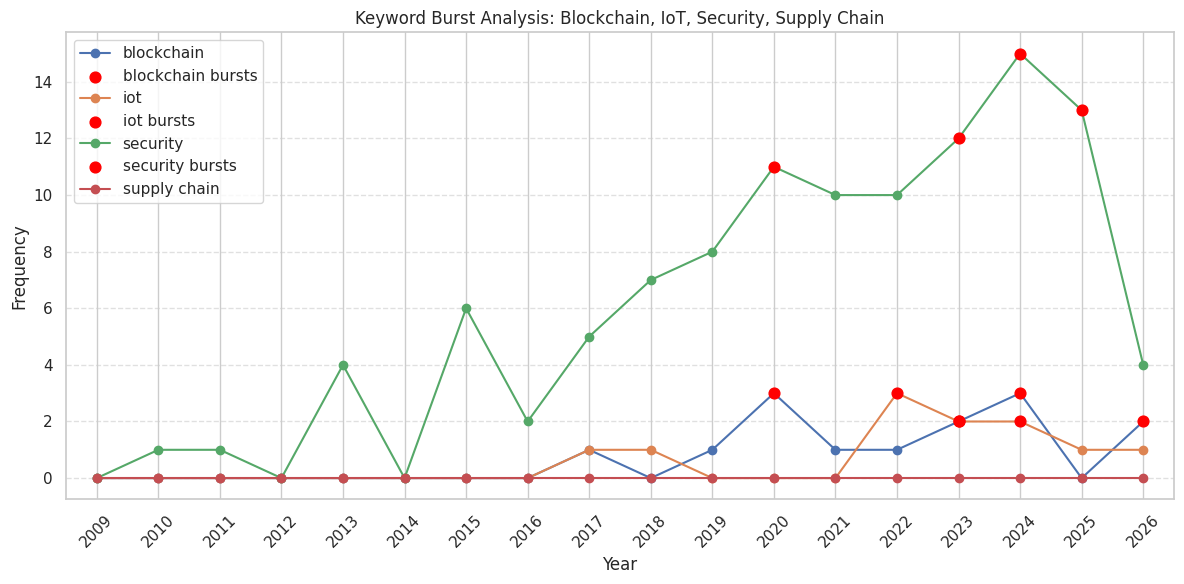

In [ ]:
# Colab-ready keyword burst analysis using a Google Drive Excel file
# Place this in a Colab cell and run. Update file_path if needed.

# Optional: install dependencies (uncomment if required)
# !pip install --quiet pandas matplotlib openpyxl

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Mount Google Drive (run interactively in Colab)
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# Path to your file on Google Drive
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# Basic existence check
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# Robust reader: try Excel first, fallback to CSV
def read_dataset(path):
    try:
        return pd.read_excel(path, engine='openpyxl')
    except Exception as e_excel:
        try:
            return pd.read_csv(path, engine='python')
        except Exception as e_csv:
            raise RuntimeError(f"Failed to read file as Excel ({e_excel}) or CSV ({e_csv}).")

df = read_dataset(file_path)

# Detect a year column and coerce to numeric
candidate_year_cols = ['Year', 'Publication_Year', 'YearPublished', 'PubYear', 'RefYear']
year_col = next((c for c in candidate_year_cols if c in df.columns), None)
if year_col is None:
    year_col = next((c for c in df.columns if 'year' in c.lower()), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Year'] = pd.to_numeric(df[year_col], errors='coerce')
df = df.dropna(subset=['Year']).copy()
df['Year'] = df['Year'].astype(int)

# Filter to a sensible range (1990-2026) as in your original code
df = df[(df['Year'] >= 1990) & (df['Year'] <= 2026)].copy()

# Prepare keywords column (normalize to lowercase, split on ';')
kw_col_candidates = ['Author Keywords', 'Keywords', 'Author_Keywords']
kw_col = next((c for c in kw_col_candidates if c in df.columns), None)
if kw_col is None:
    raise ValueError(f"No keywords column found. Available columns: {df.columns.tolist()}")

df['Keywords'] = df[kw_col].fillna('').astype(str).str.split(';').apply(
    lambda x: [kw.strip().lower() for kw in x if kw and kw.strip()]
)

# Build keyword-year frequency dictionary
keyword_year_counts = {}
for _, row in df.iterrows():
    kws = row['Keywords']
    if not kws:
        continue
    year = int(row['Year'])
    for kw in kws:
        if kw == '':
            continue
        d = keyword_year_counts.setdefault(kw, {})
        d[year] = d.get(year, 0) + 1

# Keywords to analyze (lowercase)
keywords_to_check = ["blockchain", "iot", "security", "supply chain"]

# Plotting: ensure consistent x-axis from 2009 to 2026 (as in original)
start_year = 2009
end_year = 2026
years = np.arange(start_year, end_year + 1)

plt.figure(figsize=(12, 6))
handled_burst_labels = set()
for kw in keywords_to_check:
    # Get counts series for the keyword and reindex to full year range (fill zeros)
    counts = pd.Series(keyword_year_counts.get(kw, {}))
    counts = counts.reindex(years, fill_value=0).sort_index()

    # Compute threshold and detect bursts (mean + std)
    if counts.sum() == 0 or counts.std() == 0:
        threshold = counts.mean() + counts.std()
        bursts = pd.Series(dtype=float)
    else:
        threshold = counts.mean() + counts.std()
        bursts = counts[counts > threshold]

    # Plot line
    plt.plot(counts.index, counts.values, marker='o', label=kw)

    # Plot bursts as red markers (avoid duplicate legend entries for bursts)
    if not bursts.empty:
        label = f"{kw} bursts"
        if label in handled_burst_labels:
            plt.scatter(bursts.index, bursts.values, color='red', s=60, zorder=5)
        else:
            plt.scatter(bursts.index, bursts.values, color='red', s=60, zorder=5, label=label)
            handled_burst_labels.add(label)

plt.title("Keyword Burst Analysis: Blockchain, IoT, Security, Supply Chain")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.xlim(start_year - 0.5, end_year + 0.5)
plt.xticks(years, rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


Mounted at /content/drive


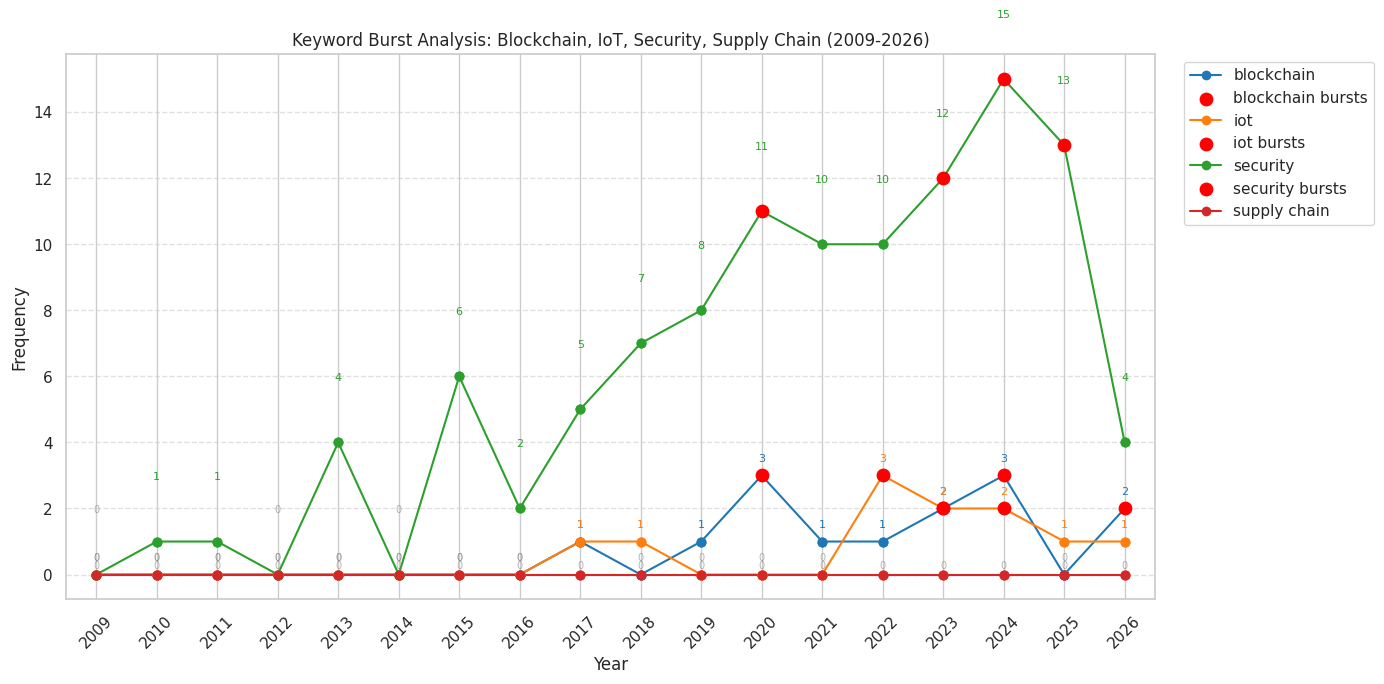

In [ ]:
# Colab-ready keyword burst analysis with numeric labels on each marker
# Run in Google Colab. Update file_path if needed.

# Optional: install dependencies
# !pip install --quiet pandas matplotlib openpyxl

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Mount Google Drive (run interactively in Colab)
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# Path to your file on Google Drive
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# Basic existence check
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# Robust reader: try Excel first, fallback to CSV
def read_dataset(path):
    try:
        return pd.read_excel(path, engine='openpyxl')
    except Exception as e_excel:
        try:
            return pd.read_csv(path, engine='python')
        except Exception as e_csv:
            raise RuntimeError(f"Failed to read file as Excel ({e_excel}) or CSV ({e_csv}).")

df = read_dataset(file_path)

# Detect a year column and coerce to numeric
candidate_year_cols = ['Year', 'Publication_Year', 'YearPublished', 'PubYear', 'RefYear']
year_col = next((c for c in candidate_year_cols if c in df.columns), None)
if year_col is None:
    year_col = next((c for c in df.columns if 'year' in c.lower()), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Year'] = pd.to_numeric(df[year_col], errors='coerce')
df = df.dropna(subset=['Year']).copy()
df['Year'] = df['Year'].astype(int)

# Filter to a sensible range (1990-2026)
df = df[(df['Year'] >= 1990) & (df['Year'] <= 2026)].copy()

# Prepare keywords column (normalize to lowercase, split on ';')
kw_col_candidates = ['Author Keywords', 'Keywords', 'Author_Keywords']
kw_col = next((c for c in kw_col_candidates if c in df.columns), None)
if kw_col is None:
    raise ValueError(f"No keywords column found. Available columns: {df.columns.tolist()}")

df['Keywords'] = df[kw_col].fillna('').astype(str).str.split(';').apply(
    lambda x: [kw.strip().lower() for kw in x if kw and kw.strip()]
)

# Build keyword-year frequency dictionary
keyword_year_counts = {}
for _, row in df.iterrows():
    kws = row['Keywords']
    if not kws:
        continue
    year = int(row['Year'])
    for kw in kws:
        if kw == '':
            continue
        d = keyword_year_counts.setdefault(kw, {})
        d[year] = d.get(year, 0) + 1

# Keywords to analyze (lowercase)
keywords_to_check = ["blockchain", "iot", "security", "supply chain"]

# Plotting: ensure consistent x-axis from 2009 to 2026
start_year = 2009
end_year = 2026
years = np.arange(start_year, end_year + 1)

plt.figure(figsize=(14, 7))
handled_burst_labels = set()
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
for i, kw in enumerate(keywords_to_check):
    # Get counts series for the keyword and reindex to full year range (fill zeros)
    counts = pd.Series(keyword_year_counts.get(kw, {}))
    counts = counts.reindex(years, fill_value=0).sort_index()

    # Compute threshold and detect bursts (mean + std)
    if counts.sum() == 0 or counts.std() == 0:
        threshold = counts.mean() + counts.std()
        bursts = pd.Series(dtype=float)
    else:
        threshold = counts.mean() + counts.std()
        bursts = counts[counts > threshold]

    # Plot line and markers
    plt.plot(counts.index, counts.values, marker='o', label=kw, color=colors[i % len(colors)])
    plt.scatter(counts.index, counts.values, color=colors[i % len(colors)], s=40, zorder=4)

    # Annotate each marker with its numeric value
    for x, y in zip(counts.index, counts.values):
        if y != 0:
            plt.text(x, y + 0.12 * max(1, counts.max()), str(int(y)),
                     ha='center', va='bottom', fontsize=8, color=colors[i % len(colors)])
        else:
            # Optionally show zeros faintly; comment out the next line to hide zeros
            plt.text(x, y + 0.12 * max(1, counts.max()), "0",
                     ha='center', va='bottom', fontsize=7, color='gray', alpha=0.6)

    # Plot bursts as red markers (avoid duplicate legend entries for bursts)
    if not bursts.empty:
        label = f"{kw} bursts"
        if label in handled_burst_labels:
            plt.scatter(bursts.index, bursts.values, color='red', s=80, zorder=6)
        else:
            plt.scatter(bursts.index, bursts.values, color='red', s=80, zorder=6, label=label)
            handled_burst_labels.add(label)

plt.title("Keyword Burst Analysis: Blockchain, IoT, Security, Supply Chain (2009-2026)")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.xlim(start_year - 0.5, end_year + 0.5)
plt.xticks(years, rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


Mounted at /content/drive


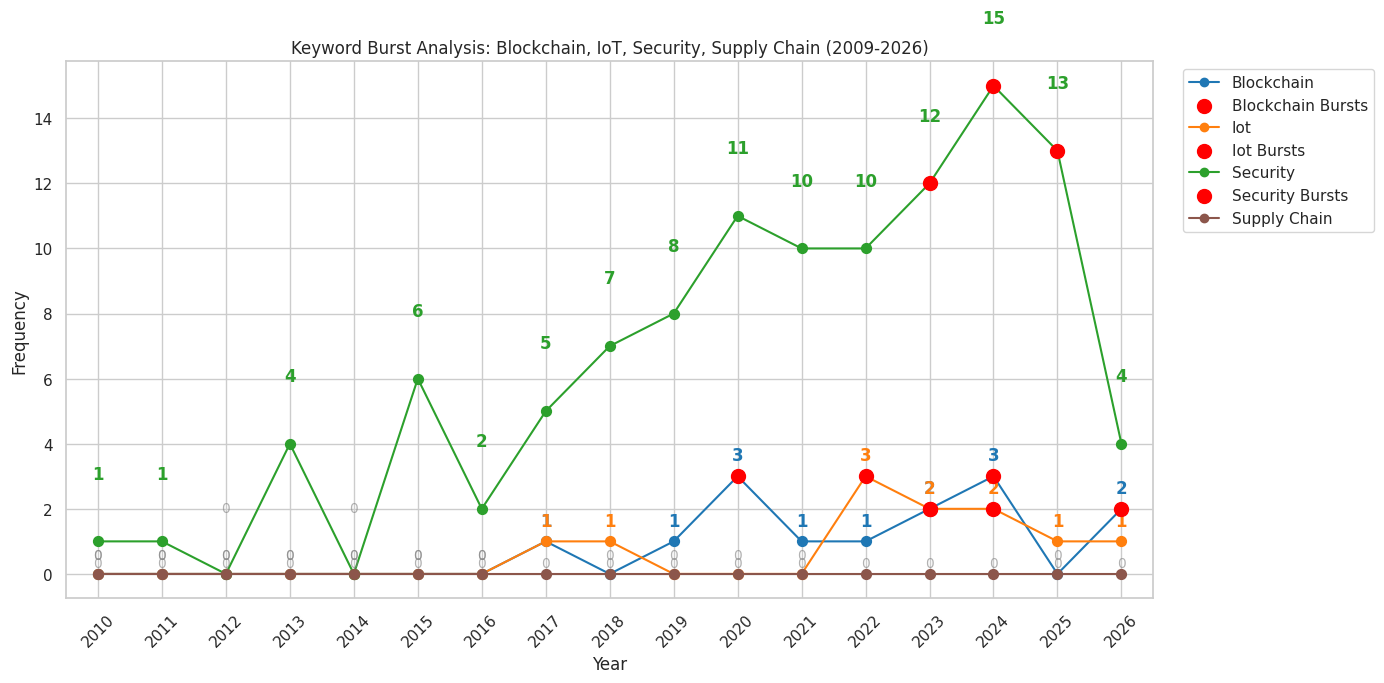

In [ ]:
# Keyword burst analysis with larger value labels, no grid, and capitalized labels
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

# Mount Drive (run interactively)
drive.mount('/content/drive', force_remount=True)

# Path to your file on Google Drive
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# Read dataset
def read_dataset(path):
    try:
        return pd.read_excel(path, engine='openpyxl')
    except Exception as e_excel:
        try:
            return pd.read_csv(path, engine='python')
        except Exception as e_csv:
            raise RuntimeError(f"Failed to read file as Excel ({e_excel}) or CSV ({e_csv}).")

df = read_dataset(file_path)

# Detect year column and coerce
candidate_year_cols = ['Year', 'Publication_Year', 'YearPublished', 'PubYear', 'RefYear']
year_col = next((c for c in candidate_year_cols if c in df.columns), None)
if year_col is None:
    year_col = next((c for c in df.columns if 'year' in c.lower()), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Year'] = pd.to_numeric(df[year_col], errors='coerce')
df = df.dropna(subset=['Year']).copy()
df['Year'] = df['Year'].astype(int)
df = df[(df['Year'] >= 1990) & (df['Year'] <= 2026)].copy()

# Keywords column detection and normalization
kw_col_candidates = ['Author Keywords', 'Keywords', 'Author_Keywords']
kw_col = next((c for c in kw_col_candidates if c in df.columns), None)
if kw_col is None:
    raise ValueError(f"No keywords column found. Available columns: {df.columns.tolist()}")

df['Keywords'] = df[kw_col].fillna('').astype(str).str.split(';').apply(
    lambda x: [kw.strip().lower() for kw in x if kw and kw.strip()]
)

# Build keyword-year frequency dictionary
keyword_year_counts = {}
for _, row in df.iterrows():
    kws = row['Keywords']
    if not kws:
        continue
    year = int(row['Year'])
    for kw in kws:
        if kw == '':
            continue
        d = keyword_year_counts.setdefault(kw, {})
        d[year] = d.get(year, 0) + 1

# Keywords to analyze (lowercase)
keywords_to_check = ["blockchain", "iot", "security", "supply chain"]

# Plotting: ensure consistent x-axis from 2010 to 2026
start_year = 2010
end_year = 2026
years = np.arange(start_year, end_year + 1)

plt.figure(figsize=(14, 7))
handled_burst_labels = set()
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:brown']

for i, kw in enumerate(keywords_to_check):
    # Get counts series for the keyword and reindex to full year range (fill zeros)
    counts = pd.Series(keyword_year_counts.get(kw, {}))
    counts = counts.reindex(years, fill_value=0).sort_index()

    # Compute threshold and detect bursts (mean + std)
    if counts.sum() == 0 or counts.std() == 0:
        threshold = counts.mean() + counts.std()
        bursts = pd.Series(dtype=float)
    else:
        threshold = counts.mean() + counts.std()
        bursts = counts[counts > threshold]

    # Capitalized label for legend (first letter of each word)
    legend_label = kw.title()

    # Plot line and markers
    plt.plot(counts.index, counts.values, marker='o', label=legend_label, color=colors[i % len(colors)])
    plt.scatter(counts.index, counts.values, color=colors[i % len(colors)], s=50, zorder=4)

    # Annotate each marker with its numeric value (increased font size)
    for x, y in zip(counts.index, counts.values):
        # Only annotate non-negative values; adjust vertical offset relative to max
        offset = 0.12 * max(1, counts.max())
        if y != 0:
            plt.text(x, y + offset, str(int(y)),
                     ha='center', va='bottom', fontsize=12, fontweight='bold', color=colors[i % len(colors)])
        else:
            # Optionally show zeros faintly; comment out to hide zeros
            plt.text(x, y + offset, "0",
                     ha='center', va='bottom', fontsize=10, color='gray', alpha=0.6)

    # Plot bursts as red markers and capitalized burst label
    if not bursts.empty:
        burst_label = f"{kw.title()} Bursts"
        if burst_label in handled_burst_labels:
            plt.scatter(bursts.index, bursts.values, color='red', s=100, zorder=6)
        else:
            plt.scatter(bursts.index, bursts.values, color='red', s=100, zorder=6, label=burst_label)
            handled_burst_labels.add(burst_label)

# Remove grid as requested
# plt.grid(axis='y', linestyle='--', alpha=0.6)  # intentionally removed

plt.title("Keyword Burst Analysis: Blockchain, IoT, Security, Supply Chain (2009-2026)")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.xlim(start_year - 0.5, end_year + 0.5)
plt.xticks(years, rotation=45)

# Legend with slightly larger font and tidy placement
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=11)
plt.tight_layout()
plt.show()


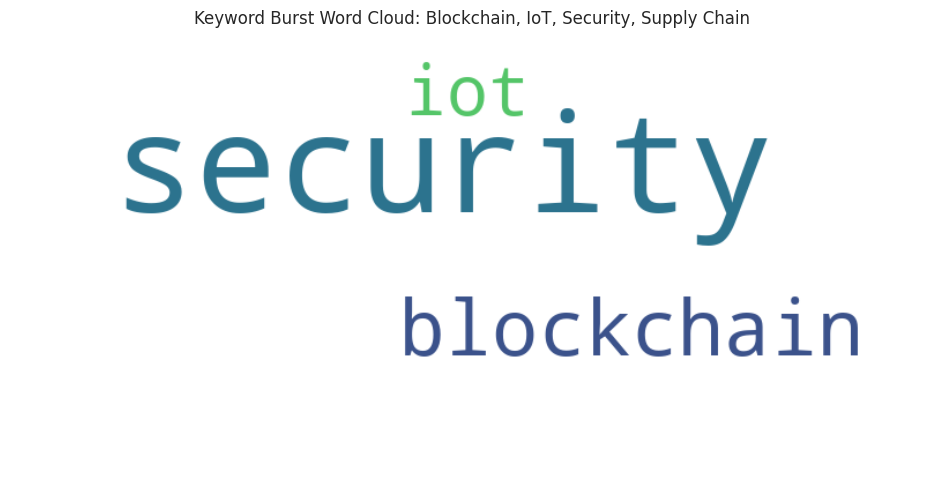

In [ ]:
# --- Step 1: Install wordcloud if not already ---
!pip install wordcloud

# --- Step 2: Import libraries ---
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# --- Step 3: Load your dataset ---
# Path to your file on Google Drive
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# Read dataset
def read_dataset(path):
    try:
        return pd.read_excel(path, engine='openpyxl')
    except Exception as e_excel:
        try:
            return pd.read_csv(path, engine='python')
        except Exception as e_csv:
            raise RuntimeError(f"Failed to read file as Excel ({e_excel}) or CSV ({e_csv}).")

df = read_dataset(file_path)

# --- Step 4: Extract year and keywords ---
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df = df.dropna(subset=['Year'])
df['Keywords'] = df['Author Keywords'].str.lower().str.split(';')

# --- Step 5: Build keyword-year frequency dictionary ---
keyword_year_counts = {}
for _, row in df.dropna(subset=['Keywords']).iterrows():
    for kw in row['Keywords']:
        kw = kw.strip()
        if kw not in keyword_year_counts:
            keyword_year_counts[kw] = {}
        keyword_year_counts[kw][row['Year']] = keyword_year_counts[kw].get(row['Year'], 0) + 1

# --- Step 6: Select burst keywords (Blockchain, IoT, Security, Supply Chain) ---
keywords_to_check = ["blockchain", "iot", "security", "supply chain"]

# Aggregate frequencies across years
burst_data = {}
for kw in keywords_to_check:
    counts = pd.Series(keyword_year_counts.get(kw, {})).sort_index()
    burst_data[kw] = counts.sum()  # total frequency across years

# --- Step 7: Generate word cloud ---
wordcloud = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(burst_data)

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Keyword Burst Word Cloud: Blockchain, IoT, Security, Supply Chain")
plt.show()


In [ ]:
# Optional: install wordcloud if not already
# !pip install --quiet wordcloud

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from wordcloud import WordCloud

# --- Step 1: Extract top 10 keywords ---
all_keywords = pd.Series([
    kw.strip().lower()
    for kws in df['Keywords'].dropna()
    for kw in kws
]).value_counts().head(10)

top_keywords = list(all_keywords.index)

# --- Step 2: Run burst detection for each top keyword ---
plt.figure(figsize=(14,8))
for kw in top_keywords:
    counts = pd.Series(keyword_year_counts.get(kw, {})).sort_index()
    counts = counts[(counts.index >= 2009) & (counts.index <= 2026)]
    threshold = counts.mean() + counts.std()
    bursts = counts[counts > threshold]
    plt.plot(counts.index, counts.values, marker='o', alpha=0.7, label=kw.title())
    plt.scatter(bursts.index, bursts.values, color='red', s=60)

plt.title("Keyword Burst Analysis: Top 10 Keywords (2009–2026)", fontsize=15, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

# --- Step 3: Create a word cloud based on frequency of top 10 keywords ---
wordcloud = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(all_keywords.to_dict())

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Top 10 Keywords", fontsize=15, fontweight='bold')
plt.show()


In [ ]:
# Optional: install wordcloud if not already
# !pip install --quiet wordcloud

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# --- Step 1: Extract keywords from 2010–2026 ---
df_filtered = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)].copy()

all_keywords_series = pd.Series([
    kw.strip().lower()
    for kws in df_filtered['Keywords'].dropna()
    for kw in kws
])

# --- Step 2: Top 10 keywords by frequency ---
top10_keywords = all_keywords_series.value_counts().head(10)

# --- Step 3: Display as a table ---
print("Top 10 Keywords (2010–2026):")
print(top10_keywords.reset_index().rename(columns={'index':'Keyword', 0:'Frequency'}))

# --- Step 4: Burst detection plot for top 10 ---
plt.figure(figsize=(14,8))
for kw in top10_keywords.index:
    counts = pd.Series(keyword_year_counts.get(kw, {})).sort_index()
    counts = counts[(counts.index >= 2010) & (counts.index <= 2026)]
    threshold = counts.mean() + counts.std()
    bursts = counts[counts > threshold]
    plt.plot(counts.index, counts.values, marker='o', alpha=0.7, label=kw.title())
    plt.scatter(bursts.index, bursts.values, color='red', s=60)

plt.title("Keyword Burst Analysis: Top 10 Keywords (2010–2026)", fontsize=15, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

# --- Step 5: Word cloud for ALL keywords ---
all_keyword_counts = all_keywords_series.value_counts()

wordcloud = WordCloud(width=1000, height=500, background_color="white").generate_from_frequencies(all_keyword_counts.to_dict())

plt.figure(figsize=(14,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of All Keywords (2010–2026)", fontsize=15, fontweight='bold')
plt.show()


In [ ]:
# Optional: install wordcloud if not already
# !pip install --quiet wordcloud

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from wordcloud import WordCloud

# --- Step 1: Filter dataset to 2010–2026 ---
df_filtered = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)].copy()

# --- Step 2: Extract all keywords ---
all_keywords_series = pd.Series([
    kw.strip().lower()
    for kws in df_filtered['Keywords'].dropna()
    for kw in kws
])

# --- Step 3: Top 10 keywords by frequency ---
top10_keywords = all_keywords_series.value_counts().head(10)

# --- Step 4: Create a table with Keyword and Frequency ---
top10_table = top10_keywords.reset_index()
top10_table.columns = ["Keyword", "Frequency"]
print("Top 10 Keywords (2010–2026):")
print(top10_table)

# --- Step 5: Burst detection plot for top 10 with value labels ---
plt.figure(figsize=(14,8))
for kw in top10_keywords.index:
    counts = pd.Series(keyword_year_counts.get(kw, {})).sort_index()
    counts = counts[(counts.index >= 2010) & (counts.index <= 2026)]
    threshold = counts.mean() + counts.std()
    bursts = counts[counts > threshold]

    # Plot line and markers
    plt.plot(counts.index, counts.values, marker='o', alpha=0.7, label=kw.title())
    plt.scatter(bursts.index, bursts.values, color='red', s=60)

    # Add value labels to each point
    max_val = max(1, counts.max())
    offset = 0.10 * max_val
    for x, y in zip(counts.index, counts.values):
        plt.text(x, y + offset, str(int(y)), ha='center', va='bottom',
                 fontsize=10, fontweight='bold')

plt.title("Keyword Burst Analysis: Top 10 Keywords (2010–2026)", fontsize=15, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=12)
plt.tight_layout()
plt.show()

# --- Step 6: Word cloud for ALL keywords (2010–2026) ---
all_keyword_counts = all_keywords_series.value_counts()

wordcloud = WordCloud(width=1000, height=500, background_color="white").generate_from_frequencies(all_keyword_counts.to_dict())

plt.figure(figsize=(14,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of All Keywords (2010–2026)", fontsize=15, fontweight='bold')
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Step 1: Filter dataset to 2010–2026 ---
df_filtered = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)].copy()

# --- Step 2: Extract all keywords ---
all_keywords_series = pd.Series([
    kw.strip().lower()
    for kws in df_filtered['Keywords'].dropna()
    for kw in kws
])

# --- Step 3: Top 10 keywords by frequency ---
top10_keywords = all_keywords_series.value_counts().head(10).index.tolist()

# --- Step 4: Build a DataFrame of yearly counts for top 10 keywords ---
years = range(2010, 2027)
keyword_counts_df = pd.DataFrame(index=years, columns=top10_keywords).fillna(0)

for kw in top10_keywords:
    counts = pd.Series(keyword_year_counts.get(kw, {}))
    counts = counts[(counts.index >= 2010) & (counts.index <= 2026)]
    keyword_counts_df[kw] = counts.reindex(years, fill_value=0)

# --- Step 5: Plot stacked area chart ---
plt.figure(figsize=(14,8))
keyword_counts_df.plot.area(alpha=0.7, figsize=(14,8), cmap="tab10")

plt.title("Stacked Area Chart: Top 10 Keywords (2010–2026)", fontsize=15, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(title="Keyword", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Step 1: Filter dataset to 2010–2026 ---
df_filtered = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)].copy()

# --- Step 2: Extract all keywords ---
all_keywords_series = pd.Series([
    kw.strip().lower()
    for kws in df_filtered['Keywords'].dropna()
    for kw in kws
])

# --- Step 3: Top 10 keywords by frequency ---
top10_keywords = all_keywords_series.value_counts().head(10).index.tolist()

# --- Step 4: Build a DataFrame of yearly counts for top 10 keywords ---
years = range(2010, 2027)
keyword_counts_df = pd.DataFrame(index=years, columns=top10_keywords).fillna(0)

for kw in top10_keywords:
    counts = pd.Series(keyword_year_counts.get(kw, {}))
    counts = counts[(counts.index >= 2010) & (counts.index <= 2026)]
    keyword_counts_df[kw] = counts.reindex(years, fill_value=0)

# Capitalize keywords for legend
keyword_counts_df.columns = [kw.title() for kw in keyword_counts_df.columns]

# --- Step 5: Plot stacked area chart ---
fig, ax = plt.subplots(figsize=(14,8))
keyword_counts_df.plot.area(alpha=0.7, cmap="tab10", ax=ax)

# Add value labels at each node
for kw in keyword_counts_df.columns:
    for x, y in zip(keyword_counts_df.index, keyword_counts_df[kw]):
        if y > 0:  # only label non-zero values
            ax.text(x, y, str(int(y)), ha='center', va='bottom',
                    fontsize=9, fontweight='bold')

plt.title("Stacked Area Chart: Top 10 Keywords (2010–2026)", fontsize=15, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(title="Keyword", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(14,8))
keyword_counts_df.plot.area(alpha=0.7, cmap="tab10", ax=ax)

# Add labels only at peak year for each keyword
for kw in keyword_counts_df.columns:
    series = keyword_counts_df[kw]
    peak_year = series.idxmax()
    peak_val = series.max()
    if peak_val > 0:
        ax.text(peak_year, peak_val + 0.5, str(int(peak_val)),
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title("Stacked Area Chart: Top 10 Keywords (2010–2026)", fontsize=15, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(title="Keyword", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
# Optional: install dependencies if not already
# !pip install --quiet pandas networkx matplotlib openpyxl

import os
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Set file path (your shared link)
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Check file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# 4. Read Excel file
df = pd.read_excel(file_path, engine='openpyxl')

# 5. Ensure Authors column exists and split by ';'
if 'Authors' not in df.columns:
    raise ValueError(f"'Authors' column not found. Available columns: {df.columns.tolist()}")

df['Authors'] = df['Authors'].fillna('').astype(str).str.split(';')

# 6. Build edges from co-authorship pairs
edges = []
for authors in df['Authors']:
    authors = [a.strip() for a in authors if a.strip()]
    if len(authors) > 1:
        for combo in combinations(set(authors), 2):
            edges.append(combo)

# 7. Create graph
G = nx.Graph()
G.add_edges_from(edges)

# 8. Plot network
plt.figure(figsize=(12,8))
nx.draw_networkx(
    G,
    node_color='lightblue',
    edge_color='gray',
    node_size=500,
    font_size=8,
    with_labels=True
)
plt.title("Author Collaboration Network", fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()


In [ ]:
# Optional: install dependencies if not already
# !pip install --quiet pandas networkx matplotlib openpyxl

import os
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Set file path
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Check file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# 4. Read Excel file
df = pd.read_excel(file_path, engine='openpyxl')

# 5. Detect year column and filter to 2026
candidate_year_cols = ['Year', 'Publication_Year', 'YearPublished', 'PubYear']
year_col = next((c for c in candidate_year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Year'] = pd.to_numeric(df[year_col], errors='coerce')
df = df[df['Year'] == 2026].copy()   # <-- restrict to 2026 only

# 6. Ensure Authors column exists and split by ';'
if 'Authors' not in df.columns:
    raise ValueError(f"'Authors' column not found. Available columns: {df.columns.tolist()}")

df['Authors'] = df['Authors'].fillna('').astype(str).str.split(';')

# 7. Build edges from co-authorship pairs
edges = []
for authors in df['Authors']:
    authors = [a.strip() for a in authors if a.strip()]
    if len(authors) > 1:
        for combo in combinations(set(authors), 2):
            edges.append(combo)

# 8. Create graph
G = nx.Graph()
G.add_edges_from(edges)

# 9. Plot network
plt.figure(figsize=(12,8))
nx.draw_networkx(
    G,
    node_color='lightblue',
    edge_color='gray',
    node_size=500,
    font_size=8,
    with_labels=True
)
plt.title("Author Collaboration Network (Year 2026)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()


In [ ]:
# Optional: install dependencies if not already
# !pip install --quiet pandas networkx matplotlib openpyxl

import os
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Set file path
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Check file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# 4. Read Excel file
df = pd.read_excel(file_path, engine='openpyxl')

# 5. Ensure 'Author Keywords' column exists
if 'Author Keywords' not in df.columns:
    raise ValueError(f"'Author Keywords' column not found. Available columns: {df.columns.tolist()}")

# 6. Split keywords by ';' and clean
df['Keywords'] = df['Author Keywords'].fillna('').astype(str).str.split(';').apply(
    lambda x: [k.strip().title() for k in x if k.strip()] if x else []
)

# 7. Build edges from co-occurring keywords
edges = []
for keywords in df['Keywords']:
    if len(keywords) > 1:
        for combo in combinations(sorted(set(keywords)), 2):
            edges.append(combo)

# 8. Create graph with weighted edges (frequency of co-occurrence)
G = nx.Graph()
for edge in edges:
    if G.has_edge(*edge):
        G[edge[0]][edge[1]]['weight'] += 1
    else:
        G.add_edge(edge[0], edge[1], weight=1)

# 9. Plot network
plt.figure(figsize=(15,10))
pos = nx.spring_layout(G, k=0.8, iterations=50)

# Node sizes proportional to degree
node_sizes = [300 + 100*G.degree(n) for n in G.nodes()]
edge_widths = [0.5*G[u][v]['weight'] for u,v in G.edges()]

nx.draw_networkx(
    G,
    pos,
    node_color='lightgreen',
    edge_color='gray',
    node_size=node_sizes,
    width=edge_widths,
    font_size=8,
    with_labels=True
)

plt.title("Keyword Co-occurrence Network", fontsize=15, fontweight='bold')
plt.axis('off')
plt.show()


In [ ]:
# Optional: install dependencies if not already
# !pip install --quiet pandas networkx matplotlib openpyxl

import os
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Set file path
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Check file exists
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# 4. Read Excel file
df = pd.read_excel(file_path, engine='openpyxl')

# 5. Detect year column and filter to 2026
candidate_year_cols = ['Year', 'Publication_Year', 'YearPublished', 'PubYear']
year_col = next((c for c in candidate_year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Year'] = pd.to_numeric(df[year_col], errors='coerce')
df = df[df['Year'] == 2026].copy()   # <-- restrict to 2026 only

# 6. Ensure 'Author Keywords' column exists
if 'Author Keywords' not in df.columns:
    raise ValueError(f"'Author Keywords' column not found. Available columns: {df.columns.tolist()}")

# 7. Split keywords by ';' and clean (capitalize first letters)
df['Keywords'] = df['Author Keywords'].fillna('').astype(str).str.split(';').apply(
    lambda x: [k.strip().title() for k in x if k.strip()] if x else []
)

# 8. Build edges from co-occurring keywords
edges = []
for keywords in df['Keywords']:
    if len(keywords) > 1:
        for combo in combinations(sorted(set(keywords)), 2):
            edges.append(combo)

# 9. Create graph with weighted edges (frequency of co-occurrence)
G = nx.Graph()
for edge in edges:
    if G.has_edge(*edge):
        G[edge[0]][edge[1]]['weight'] += 1
    else:
        G.add_edge(edge[0], edge[1], weight=1)

# 10. Plot network
plt.figure(figsize=(15,10))
pos = nx.spring_layout(G, k=0.8, iterations=50)

# Node sizes proportional to degree
node_sizes = [300 + 100*G.degree(n) for n in G.nodes()]
edge_widths = [0.5*G[u][v]['weight'] for u,v in G.edges()]

nx.draw_networkx(
    G,
    pos,
    node_color='lightgreen',
    edge_color='gray',
    node_size=node_sizes,
    width=edge_widths,
    font_size=8,
    with_labels=True
)

plt.title("Keyword Co-occurrence Network (Year 2026)", fontsize=15, fontweight='bold')
plt.axis('off')
plt.show()


In [ ]:
# Required libraries
import os
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
import re
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Define file path
csv_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Load file
df = pd.read_excel(csv_path, engine='openpyxl')

# 4. Detect and coerce year column
year_cols = ['Publication_Year', 'Year', 'YearPublished', 'PubYear']
year_col = next((c for c in year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Publication_Year'] = pd.to_numeric(df[year_col], errors='coerce')

# 5. Filter to year 2026 only
df = df[df['Publication_Year'] == 2026].copy()

# 6. Prepare and normalize keywords
kw_col = 'Author Keywords'
if kw_col not in df.columns:
    raise ValueError(f"Column '{kw_col}' not found in the file")

def normalize_keyword(k):
    k = str(k).lower().strip()
    k = re.sub(r'[^\w\s-]', '', k)   # remove punctuation
    k = re.sub(r'\s+', ' ', k)       # collapse whitespace
    return k.title()                 # capitalize for clarity

def split_and_normalize(cell):
    if pd.isna(cell) or str(cell).strip() == '':
        return []
    parts = [p.strip() for p in str(cell).split(';') if p.strip()]
    parts = [normalize_keyword(p) for p in parts]
    return list(dict.fromkeys(parts))  # remove duplicates, preserve order

df['Keywords'] = df[kw_col].apply(split_and_normalize)

# 7. Build weighted co-occurrence counts
pair_counts = Counter()
for kws in df['Keywords']:
    if len(kws) < 2:
        continue
    for a, b in combinations(sorted(kws), 2):
        pair_counts[(a, b)] += 1

# 8. Create weighted graph
G = nx.Graph()
for (a, b), w in pair_counts.items():
    G.add_edge(a, b, weight=w)

# 9. Optional: keep only top-N keywords by incident weight
top_n = 50
if top_n:
    node_scores = {n: sum(d.get('weight', 1) for _, _, d in G.edges(n, data=True)) for n in G.nodes()}
    top_nodes = set(sorted(node_scores, key=node_scores.get, reverse=True)[:top_n])
    G = G.subgraph(top_nodes).copy()

# 10. Layout and drawing
pos = nx.spring_layout(G, k=0.8, iterations=100, seed=42)
node_weights = dict(G.degree(weight='weight'))
node_sizes = [200 + 60 * node_weights.get(n, 0) for n in G.nodes()]
edge_widths = [max(0.5, 0.3 * d.get('weight', 1)) for _, _, d in G.edges(data=True)]

plt.figure(figsize=(15,10))
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='lightgreen', linewidths=0.5)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color='gray', alpha=0.7)

# Show labels only for nodes above a degree threshold
label_threshold = 1
labels = {n: n for n, d in G.degree() if d > label_threshold}
nx.draw_networkx_labels(G, pos, labels, font_size=9)

plt.title("Keyword Co-occurrence Network (Year 2026)", fontsize=15, fontweight='bold')
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd

# --- Convert pair_counts to DataFrame ---
pair_df = pd.DataFrame(
    [(a, b, w) for (a, b), w in pair_counts.items()],
    columns=["Keyword 1", "Keyword 2", "Co-occurrence Count"]
)

# --- Sort and select top 10 ---
top10_pairs = pair_df.sort_values("Co-occurrence Count", ascending=False).head(10)

# --- Display table ---
print("Top 10 Keyword Pairs in 2026:")
print(top10_pairs.to_string(index=False))


In [ ]:
import pandas as pd

# --- Filter dataset to 2010–2026 ---
df_filtered = df[(df['Publication_Year'] >= 2010) & (df['Publication_Year'] <= 2026)].copy()

# --- Extract keywords ---
all_keywords_series = pd.Series([
    kw.strip().title()   # capitalize for readability
    for kws in df_filtered['Author Keywords'].dropna().astype(str).str.split(';')
    for kw in kws if kw.strip()
])

# --- Count frequencies ---
keyword_counts = all_keywords_series.value_counts()

# --- Top 25 keywords ---
top25_keywords = keyword_counts.head(25).reset_index()
top25_keywords.columns = ["Keyword", "Frequency"]

# --- Display table ---
print("Top 25 Keywords (2010–2026):")
print(top25_keywords.to_string(index=False))


In [ ]:
import pandas as pd
from itertools import combinations
from collections import Counter
import re

# --- Filter dataset to 2010–2026 ---
df_filtered = df[(df['Publication_Year'] >= 2010) & (df['Publication_Year'] <= 2026)].copy()

# --- Normalize keywords ---
def normalize_keyword(k):
    k = str(k).lower().strip()
    k = re.sub(r'[^\w\s-]', '', k)   # remove punctuation
    k = re.sub(r'\s+', ' ', k)       # collapse whitespace
    return k.title()                 # capitalize for readability

def split_and_normalize(cell):
    if pd.isna(cell) or str(cell).strip() == '':
        return []
    parts = [p.strip() for p in str(cell).split(';') if p.strip()]
    parts = [normalize_keyword(p) for p in parts]
    return list(dict.fromkeys(parts))  # remove duplicates, preserve order

df_filtered['Keywords'] = df_filtered['Author Keywords'].apply(split_and_normalize)

# --- Build weighted co-occurrence counts ---
pair_counts = Counter()
for kws in df_filtered['Keywords']:
    if len(kws) < 2:
        continue
    for a, b in combinations(sorted(kws), 2):
        pair_counts[(a, b)] += 1

# --- Convert to DataFrame ---
pair_df = pd.DataFrame(
    [(a, b, w) for (a, b), w in pair_counts.items()],
    columns=["Keyword 1", "Keyword 2", "Co-occurrence Count"]
)

# --- Sort and select top 25 ---
top25_pairs = pair_df.sort_values("Co-occurrence Count", ascending=False).head(25)

# --- Display table ---
print("Top 25 Keyword Pairs (2010–2026):")
print(top25_pairs.to_string(index=False))


In [ ]:
import matplotlib.pyplot as plt

# --- Plot horizontal bar chart of top 25 keyword pairs ---
plt.figure(figsize=(12,8))

# Build labels as "Keyword1 + Keyword2"
labels = top25_pairs.apply(lambda row: f"{row['Keyword 1']} + {row['Keyword 2']}", axis=1)

plt.barh(labels, top25_pairs["Co-occurrence Count"], color="skyblue")
plt.xlabel("Co-occurrence Count", fontsize=12)
plt.ylabel("Keyword Pair", fontsize=12)
plt.title("Top 25 Keyword Pairs (2010–2026)", fontsize=14, fontweight="bold")

# Invert y-axis so highest counts appear at the top
plt.gca().invert_yaxis()

# Add counts at the end of bars
for i, v in enumerate(top25_pairs["Co-occurrence Count"]):
    plt.text(v + 0.5, i, str(v), va="center", fontsize=9)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Load file ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Print all columns to identify year reference ---
print("Available columns:", df.columns.tolist())

# --- Detect and coerce year column ---
year_cols = ['Reference_Year', 'Year', 'Publication_Year', 'YearPublished', 'PubYear']
year_col = next((c for c in year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['RefYear'] = pd.to_numeric(df[year_col], errors='coerce')
df.dropna(subset=['RefYear'], inplace=True)
df['RefYear'] = df['RefYear'].astype(int)

# --- Group counts by year ---
rpys_counts = df.groupby('RefYear').size()

# --- Plot ---
plt.figure(figsize=(12,6))
plt.plot(rpys_counts.index, rpys_counts.values, color='blue', marker='o', linewidth=2)
plt.title("Publication Year Distribution (Proxy for RPYS)", fontsize=14, fontweight='bold')
plt.xlabel("Publication Year", fontsize=12)
plt.ylabel("Number of Publications", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Define file path
csv_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Load file
df = pd.read_excel(csv_path, engine='openpyxl')


# --- Print all columns to identify year reference ---
print("Available columns:", df.columns.tolist())

# --- Detect and coerce year column ---
year_cols = ['Reference_Year', 'Year', 'Publication_Year', 'YearPublished', 'PubYear']
year_col = next((c for c in year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['RefYear'] = pd.to_numeric(df[year_col], errors='coerce')
df.dropna(subset=['RefYear'], inplace=True)
df['RefYear'] = df['RefYear'].astype(int)

# --- Group counts by year ---
rpys_counts = df.groupby('RefYear').size()


# --- Plot ---
plt.figure(figsize=(12,6))

for x, y in zip(rpys_counts.index, rpys_counts.values):
    plt.text(x, y+0.5, str(y), ha='center', fontsize=12)

plt.plot(rpys_counts.index, rpys_counts.values, color='blue', marker='o', linewidth=2)
plt.title("Publication Year Distribution (Proxy for RPYS)", fontsize=14, fontweight='bold')
plt.xlabel("Publication Year", fontsize=12)
plt.ylabel("Number of Publications", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# --- Plot with values at each node ---
plt.figure(figsize=(12,6))
plt.plot(rpys_counts.index, rpys_counts.values, color='blue', marker='o', linewidth=2)

# Annotate each point with its value (larger, bold, with background)
for x, y in zip(rpys_counts.index, rpys_counts.values):
    plt.text(
        x, y+1, str(y),
        ha='center', va='bottom',
        fontsize=11, fontweight='bold',
        color='black',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2)
    )

plt.title("Publication Year Distribution (Proxy for RPYS)", fontsize=14, fontweight='bold')
plt.xlabel("Publication Year", fontsize=12)
plt.ylabel("Number of Publications", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# --- Layout and drawing parameters ---
pos = nx.spring_layout(G, k=0.8, iterations=100, seed=42)

# Node weights (degree weighted by edge weights)
node_weights = dict(G.degree(weight='weight'))
node_sizes = [200 + 60 * node_weights.get(n, 0) for n in G.nodes()]
edge_widths = [max(0.5, 0.3 * d.get('weight', 1)) for _, _, d in G.edges(data=True)]

plt.figure(figsize=(15,10))
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='lightgreen', linewidths=0.5)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color='gray', alpha=0.7)

# --- Labels: keyword + node value ---
labels = {n: f"{n} ({node_weights.get(n,0)})" for n in G.nodes()}
nx.draw_networkx_labels(G, pos, labels, font_size=9)

plt.title("Keyword Co-occurrence Network with Node Values", fontsize=15, fontweight='bold')
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 2. Define file path
csv_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Load file
df = pd.read_excel(csv_path, engine='openpyxl')


# Choose the column that contains the year values
candidate_cols = ['Reference_Year', 'RefYear', 'Year', 'Publication_Year', 'YearPublished', 'PubYear']
year_col = next((c for c in candidate_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available: {df.columns.tolist()}")

# Coerce to numeric and drop invalids
df['RefYear'] = pd.to_numeric(df[year_col], errors='coerce')
df = df.dropna(subset=['RefYear']).copy()
df['RefYear'] = df['RefYear'].astype(int)

# Compute counts
rpys_counts = df.groupby('RefYear').size().sort_index()

# Force x-axis to include 2010 (change start_year if needed)
start_year = 2010
end_year = max(rpys_counts.index.max(), 2026)  # ensure at least up to 2026
full_index = range(start_year, end_year + 1)
rpys_counts = rpys_counts.reindex(full_index, fill_value=0)

# Plot
plt.figure(figsize=(12,6))
plt.plot(rpys_counts.index, rpys_counts.values, color='blue', marker='o', linewidth=2)
plt.title("Publication Year Distribution (Proxy for RPYS)")
plt.xlabel("Publication Year")
plt.ylabel("Number of Publications")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Annotate peaks if any
max_val = rpys_counts.max()
if max_val > 0:
    peak_years = rpys_counts[rpys_counts == max_val].index.tolist()
    for y in peak_years:
        plt.annotate(f"{y}: {int(max_val)}", xy=(y, max_val), xytext=(0,8),
                     textcoords='offset points', ha='center', fontsize=9, fontweight='bold')

plt.xticks(list(full_index), rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
import re
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Define file path
csv_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 3. Load file
df = pd.read_excel(csv_path, engine='openpyxl')

# 4. Detect and coerce year column
year_cols = ['Publication_Year', 'Year', 'YearPublished', 'PubYear']
year_col = next((c for c in year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Publication_Year'] = pd.to_numeric(df[year_col], errors='coerce')

# 5. Filter to year 2026 only
df_2026_keywords = df[df['Publication_Year'] == 2026].copy()

# 6. Prepare and normalize keywords
kw_col = 'Author Keywords'
if kw_col not in df_2026_keywords.columns:
    raise ValueError(f"Column '{kw_col}' not found in the file")

def normalize_keyword(k):
    k = str(k).lower().strip()
    k = re.sub(r'[^\w\s-]', '', k)   # remove punctuation
    k = re.sub(r'\s+', ' ', k)       # collapse whitespace
    return k.title()                 # capitalize for clarity

def split_and_normalize(cell):
    if pd.isna(cell) or str(cell).strip() == '':
        return []
    parts = [p.strip() for p in str(cell).split(';') if p.strip()]
    parts = [normalize_keyword(p) for p in parts]
    return list(dict.fromkeys(parts))  # remove duplicates, preserve order

df_2026_keywords['Keywords'] = df_2026_keywords[kw_col].apply(split_and_normalize)

# 7. Build weighted co-occurrence counts
pair_counts = Counter()
for kws in df_2026_keywords['Keywords']:
    if len(kws) < 2:
        continue
    for a, b in combinations(sorted(kws), 2):
        pair_counts[(a, b)] += 1

# 8. Create weighted graph
G = nx.Graph()
for (a, b), w in pair_counts.items():
    G.add_edge(a, b, weight=w)

# 9. Optional: keep only top-N keywords by incident weight (from previous cell logic)
top_n = 50
if top_n and G.nodes(): # Check if G has nodes before trying to filter
    node_scores = {n: sum(d.get('weight', 1) for _, _, d in G.edges(n, data=True)) for n in G.nodes()}
    top_nodes = set(sorted(node_scores, key=node_scores.get, reverse=True)[:top_n])
    G = G.subgraph(top_nodes).copy()

# --- Top keywords by weighted degree ---
node_scores = dict(G.degree(weight='weight'))
top_keywords = sorted(node_scores.items(), key=lambda x: x[1], reverse=True)[:20]

# --- Top co-occurring pairs ---

pairs_df = (
    pd.DataFrame(
        [(a, b, d['weight']) for a, b, d in G.edges(data=True)],
        columns=['kw1', 'kw2', 'count']
    )
    .sort_values('count', ascending=False)
)

# Save top 20 pairs to CSV
pairs_df.head(20).to_csv('top_keyword_pairs_2026.csv', index=False)

# --- Diagnostics ---
print("Rows total:", len(df_2026_keywords))
print("Columns:", df_2026_keywords.columns.tolist())
print("Sample year values:", df_2026_keywords['Publication_Year'].dropna().unique()[:10])
print("Sample Author Keywords (first 5):")
print(df_2026_keywords['Author Keywords'].head(5).tolist())

In [ ]:
import pandas as pd
import plotly.graph_objects as go
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Example: Load your dataset (replace with actual file if needed)
csv_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Sankey structure (replace with actual clusters) ---
# Define nodes (clusters or categories)
labels = [
    "Cluster A", "Cluster B", "Cluster C",   # source clusters
    "Topic 1", "Topic 2", "Topic 3"          # target topics
]

# Define links (flows between clusters and topics)
source = [0, 0, 1, 1, 2, 2]   # indices of source nodes
target = [3, 4, 4, 5, 3, 5]   # indices of target nodes
value  = [10, 5, 8, 4, 6, 7]  # flow values (replace with your counts)

# Build Sankey diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=20,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,
        color="lightblue"
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color="rgba(0,150,200,0.4)"
    )
)])
labels = [
    "Cluster A", "Cluster B", "Cluster C",   # source clusters
    "Topic 1", "Topic 2", "Topic 3"          # target topics
]
fig.update_layout(title_text="Sankey Structure (replace with actual clusters)", font_size=12)
fig.show()


In [ ]:
import pandas as pd
import plotly.graph_objects as go
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Load your dataset (replace with actual file if needed)
csv_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Sankey structure (replace with actual clusters/topics) ---
# Define nodes (clusters or categories)
labels = [
    "Cluster A", "Cluster B", "Cluster C",   # source clusters
    "Topic 1", "Topic 2", "Topic 3"          # target topics
]

# Define links (flows between clusters and topics)
source = [0, 0, 1, 1, 2, 2]   # indices of source nodes
target = [3, 4, 4, 5, 3, 5]   # indices of target nodes
value  = [10, 5, 8, 4, 6, 7]  # flow values (replace with your counts)

# Build Sankey diagram
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=20,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,          # appended labels used here
        color="lightblue"
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        color="rgba(0,150,200,0.4)"
    )
)])

fig.update_layout(title_text="Sankey Structure (replace with actual clusters)", font_size=12)
fig.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Print all columns to identify year reference ---
print("Available columns:", df.columns.tolist())

# --- Detect and coerce year column ---
year_cols = ['Reference_Year', 'Year', 'Publication_Year', 'YearPublished', 'PubYear']
year_col = next((c for c in year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['RefYear'] = pd.to_numeric(df[year_col], errors='coerce')
df.dropna(subset=['RefYear'], inplace=True)
df['RefYear'] = df['RefYear'].astype(int)

# --- Group counts by year ---
rpys_counts = df.groupby('RefYear').size()

# --- Plot with values at each node ---
plt.figure(figsize=(12,6))
plt.plot(rpys_counts.index, rpys_counts.values, color='blue', marker='o', linewidth=2)

# Annotate each point with its value (larger, bold, with background box)
for x, y in zip(rpys_counts.index, rpys_counts.values):
    plt.text(
        x, y+1, str(y),
        ha='center', va='bottom',
        fontsize=11, fontweight='bold',
        color='black',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=2)
    )

plt.title("Publication Year Distribution (Proxy for RPYS)", fontsize=14, fontweight='bold')
plt.xlabel("Publication Year", fontsize=12)
plt.ylabel("Number of Publications", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# top keywords by weighted degree
node_scores = dict(G.degree(weight='weight'))
top_keywords = sorted(node_scores.items(), key=lambda x: x[1], reverse=True)[:20]

# top co-occurring pairs
import pandas as pd
pairs_df = pd.DataFrame(((a,b,d['weight']) for a,b,d in G.edges(data=True)),
                        columns=['kw1','kw2','count']).sort_values('count', ascending=False)
pairs_df.head(20).to_csv('top_keyword_pairs_2026.csv', index=False)
print("Rows total:", len(df_2026_keywords))
print("Columns:", df_2026_keywords.columns.tolist())
print("Sample year values:", df_2026_keywords['Publication_Year'].dropna().unique()[:10])
print("Sample Author Keywords (first 5):")
print(df_2026_keywords['Author Keywords'].head(5).tolist())

In [ ]:
# Replace file_path with your actual file path before running.

import pandas as pd
import networkx as nx
from itertools import combinations
from collections import Counter
import matplotlib.pyplot as plt
import re
import os
import seaborn as sns

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Detect and coerce year column ---
year_cols = ['Publication_Year', 'Year', 'YearPublished', 'PubYear']
for c in year_cols:
    if c in df.columns:
        df['Publication_Year'] = pd.to_numeric(df[c], errors='coerce')
        break
if 'Publication_Year' not in df.columns:
    df['Publication_Year'] = pd.to_numeric(df.get('Year'), errors='coerce')

# --- Filter to 2026 only ---
df = df[df['Publication_Year'] == 2026].copy()

# --- Check presence of keywords column ---
kw_col = 'Author Keywords'
if kw_col not in df.columns:
    raise ValueError(f"Column '{kw_col}' not found. Available columns: {df.columns.tolist()}")

# --- Normalize keywords ---
def normalize_keyword(k):
    k = str(k).lower().strip()
    k = re.sub(r'[^\w\s-]', '', k)   # remove punctuation
    k = re.sub(r'\s+', ' ', k)       # collapse whitespace
    return k

def split_and_normalize(cell, delimiter=';'):
    if pd.isna(cell) or str(cell).strip() == '':
        return []
    parts = [p.strip() for p in str(cell).split(delimiter) if p.strip()]
    parts = [normalize_keyword(p) for p in parts]
    seen, out = set(), []
    for p in parts:
        if p and p not in seen:
            seen.add(p)
            out.append(p)
    return out

# Try ';' first, then fallback to ',' if no keywords parsed
df['Keywords'] = df[kw_col].apply(lambda c: split_and_normalize(c, delimiter=';'))
if df['Keywords'].map(len).sum() == 0:
    df['Keywords'] = df[kw_col].apply(lambda c: split_and_normalize(c, delimiter=','))

# --- Build pair counts and graph ---
pair_counts = Counter()
for kws in df['Keywords']:
    if len(kws) < 2:
        continue
    for a, b in combinations(sorted(kws), 2):
        pair_counts[(a, b)] += 1

if len(pair_counts) == 0:
    raise ValueError("No co-occurrence pairs found for 2026. Check keywords and delimiters.")

G = nx.Graph()
for (a, b), w in pair_counts.items():
    G.add_edge(a, b, weight=w)

# --- Top keywords by weighted degree ---
node_scores = dict(G.degree(weight='weight'))
top_n = 20
top_keywords = sorted(node_scores.items(), key=lambda x: x[1], reverse=True)[:top_n]
top_keywords_df = pd.DataFrame(top_keywords, columns=['keyword', 'weighted_degree'])

# --- Top co-occurring pairs ---
pairs_df = pd.DataFrame(
    [(a, b, d['weight']) for a, b, d in G.edges(data=True)],
    columns=['kw1', 'kw2', 'count']
).sort_values('count', ascending=False)
top_pairs_df = pairs_df.head(20).reset_index(drop=True)

# --- Print tables ---
print("Top keywords by weighted degree (2026):")
print(top_keywords_df.to_string(index=False))
print("\nTop co-occurring keyword pairs (2026):")
print(top_pairs_df.to_string(index=False))

# --- Save pairs CSV ---
pairs_csv = "top_keyword_pairs_2026.csv"
pairs_df.to_csv(pairs_csv, index=False)
print(f"\nSaved full pairs table to: {os.path.abspath(pairs_csv)}")

# --- Plot bar charts with numeric labels ---
sns.set_style('whitegrid')

# 1) Top keywords bar chart
plt.figure(figsize=(10,6))
ax1 = plt.gca()
top_keywords_df_sorted = top_keywords_df.sort_values('weighted_degree', ascending=True)
ax1.barh(top_keywords_df_sorted['keyword'], top_keywords_df_sorted['weighted_degree'], color='skyblue')
for i, (kw, val) in enumerate(zip(top_keywords_df_sorted['keyword'], top_keywords_df_sorted['weighted_degree'])):
    ax1.text(val + 0.1, i, str(int(val)), va='center', fontsize=9)
ax1.set_xlabel('Weighted degree (co-occurrence count)')
ax1.set_title('Top Keywords by Weighted Degree (2026)')
plt.tight_layout()
plt.show()

# 2) Top pairs bar chart
plt.figure(figsize=(12,6))
ax2 = plt.gca()
top_pairs_plot = top_pairs_df.copy()
top_pairs_plot['pair'] = top_pairs_plot['kw1'] + "  |  " + top_pairs_plot['kw2']
top_pairs_plot = top_pairs_plot.sort_values('count', ascending=True)
ax2.barh(top_pairs_plot['pair'], top_pairs_plot['count'], color='lightgreen')
for i, (pair, val) in enumerate(zip(top_pairs_plot['pair'], top_pairs_plot['count'])):
    ax2.text(val + 0.05, i, str(int(val)), va='center', fontsize=9)
ax2.set_xlabel('Co-occurrence count (number of 2026 papers)')
ax2.set_title('Top Co-occurring Keyword Pairs (2026)')
plt.tight_layout()
plt.show()

# --- Save top tables ---
top_keywords_df.to_csv("top_keywords_2026.csv", index=False)
top_pairs_df.to_csv("top_pairs_top20_2026.csv", index=False)
print("Saved top keywords to top_keywords_2026.csv and top 20 pairs to top_pairs_top20_2026.csv")


In [ ]:
import pandas as pd
import networkx as nx
from itertools import combinations
from collections import Counter
import matplotlib.pyplot as plt
import re
import os
import seaborn as sns # Import seaborn

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')


# --- Year detection and filter to 2026 ---
year_cols = ['Publication_Year', 'Year', 'YearPublished', 'PubYear']
for c in year_cols:
    if c in df.columns:
        df['Publication_Year'] = pd.to_numeric(df[c], errors='coerce')
        break
df = df[df['Publication_Year'] == 2026].copy()

kw_col = 'Author Keywords'
if kw_col not in df.columns:
    raise ValueError(f"Column '{kw_col}' not found. Available: {df.columns.tolist()}")

# --- Normalization (for matching) ---
def normalize_keyword(k):
    k = str(k).lower().strip()
    k = re.sub(r'[^​\w\s-]', '', k)
    k = re.sub(r'\s+', ' ', k)
    return k

def split_and_normalize(cell, delimiter=';'):
    if pd.isna(cell) or str(cell).strip() == '':
        return []
    parts = [p.strip() for p in str(cell).split(delimiter) if p.strip()]
    parts = [normalize_keyword(p) for p in parts]
    seen = set(); out = []
    for p in parts:
        if p and p not in seen:
            seen.add(p); out.append(p)
    return out

df['Keywords'] = df[kw_col].apply(lambda c: split_and_normalize(c, delimiter=';'))
if df['Keywords'].map(len).sum() == 0:
    df['Keywords'] = df[kw_col].apply(lambda c: split_and_normalize(c, delimiter=','))

# --- Build weighted co-occurrence counts ---
pair_counts = Counter()
for kws in df['Keywords']:
    if len(kws) < 2:
        continue
    for a, b in combinations(sorted(kws), 2):
        pair_counts[(a, b)] += 1

if not pair_counts:
    raise ValueError("No co-occurrence pairs found for 2026. Check keywords/delimiters.")

G = nx.Graph()
for (a, b), w in pair_counts.items():
    G.add_edge(a, b, weight=w)

# --- Top keywords by weighted degree (internal keys are normalized) ---
node_scores = dict(G.degree(weight='weight'))
top_n = 20
top_keywords = sorted(node_scores.items(), key=lambda x: x[1], reverse=True)[:top_n]

# Convert normalized keywords to Title Case for display
top_keywords_df = pd.DataFrame(top_keywords, columns=['keyword_norm', 'weighted_degree'])
top_keywords_df['keyword'] = top_keywords_df['keyword_norm'].str.replace('-', ' ').str.title()
top_keywords_df = top_keywords_df[['keyword', 'weighted_degree']]

# --- Top co-occurring pairs (display in Title Case) ---
pairs_df = pd.DataFrame(((a,b,d['weight']) for a,b,d in G.edges(data=True)),
                        columns=['kw1_norm','kw2_norm','count']).sort_values('count', ascending=False)
pairs_df['kw1'] = pairs_df['kw1_norm'].str.replace('-', ' ').str.title()
pairs_df['kw2'] = pairs_df['kw2_norm'].str.replace('-', ' ').str.title()
top_pairs_df = pairs_df.head(20)[['kw1','kw2','count']].reset_index(drop=True)

# --- Save CSVs ---
top_keywords_df.to_csv("top_keywords_2026.csv", index=False)
pairs_df.to_csv("top_keyword_pairs_2026.csv", index=False)

# --- Plotting (Title Case labels) ---
sns.set_style('whitegrid') # Changed from plt.style.use('seaborn-whitegrid') to sns.set_style('whitegrid')

# Top keywords bar chart
plt.figure(figsize=(10,6))
kw_plot = top_keywords_df.sort_values('weighted_degree', ascending=True)
plt.barh(kw_plot['keyword'], kw_plot['weighted_degree'], color='skyblue')
for i, (kw, val) in enumerate(zip(kw_plot['keyword'], kw_plot['weighted_degree'])):
    plt.text(val + 0.1, i, str(int(val)), va='center', fontsize=9)
plt.xlabel('Weighted degree (co-occurrence count)')
plt.title('Top Keywords by Weighted Degree (2026)')
plt.tight_layout()
plt.show()

# Top pairs bar chart
plt.figure(figsize=(12,6))
pairs_plot = top_pairs_df.copy()
pairs_plot['pair'] = pairs_plot['kw1'] + "  |  " + pairs_plot['kw2']
pairs_plot = pairs_plot.sort_values('count', ascending=True)
plt.barh(pairs_plot['pair'], pairs_plot['count'], color='lightgreen')
for i, (pair, val) in enumerate(zip(pairs_plot['pair'], pairs_plot['count'])):
    plt.text(val + 0.05, i, str(int(val)), va='center', fontsize=9)
plt.xlabel('Co-occurrence count (number of 2026 papers)')
plt.title('Top Co-occurring Keyword Pairs (2026)')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Load dataset
csv_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Detect year column ---
year_cols = ['Publication_Year', 'Year', 'YearPublished', 'PubYear']
year_col = next((c for c in year_cols if c in df.columns), None)
if year_col is None:
    raise ValueError(f"No year column found. Available columns: {df.columns.tolist()}")

df['Year'] = pd.to_numeric(df[year_col], errors='coerce')
df.dropna(subset=['Year'], inplace=True)
df['Year'] = df['Year'].astype(int)

# --- Keyword column check ---
kw_col = 'Author Keywords'
if kw_col not in df.columns:
    raise ValueError(f"Column '{kw_col}' not found. Available columns: {df.columns.tolist()}")

# --- Split keywords ---
df['Keywords'] = df[kw_col].fillna('').apply(lambda x: [kw.strip().lower() for kw in str(x).split(';') if kw.strip()])

# --- Build keyword-year counts ---
records = []
for _, row in df.iterrows():
    for kw in row['Keywords']:
        records.append((kw, row['Year']))
kw_df = pd.DataFrame(records, columns=['Keyword', 'Year'])

# --- Burst detection: year-to-year differences ---
kw_counts = kw_df.groupby(['Keyword','Year']).size().reset_index(name='count')
kw_counts['prev_count'] = kw_counts.groupby('Keyword')['count'].shift(1).fillna(0)
kw_counts['burst'] = kw_counts['count'] - kw_counts['prev_count']

# --- Select top bursts ---
top_bursts = kw_counts.sort_values('burst', ascending=False).head(10)

# --- Plot bursts ---
plt.figure(figsize=(12,6))
for kw in top_bursts['Keyword'].unique():
    subset = kw_counts[kw_counts['Keyword'] == kw]
    plt.plot(subset['Year'], subset['count'], marker='o', linewidth=2, label=kw)
    # Annotate values
    for x, y in zip(subset['Year'], subset['count']):
        plt.text(x, y+0.5, str(y), ha='center', fontsize=9, fontweight='bold',
                 bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))

plt.title("Keyword Burst Analysis (Top 10 Bursts)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Keyword Frequency", fontsize=12)
plt.legend(title="Keywords", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Logistic growth function ---
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# Ensure 'Year' column is numeric
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df.dropna(subset=['Year'], inplace=True)
df['Year'] = df['Year'].astype(int)

# --- Group counts by year ---
annual_counts = df.groupby('Year').size()
years = annual_counts.index.values
counts = annual_counts.values

# --- Fit logistic curve ---
params, _ = curve_fit(logistic, years, counts, p0=[max(counts), 0.1, np.median(years)])

# --- Plot actual vs logistic fit ---
plt.figure(figsize=(10,6))
plt.scatter(years, counts, label="Actual Publications", color="blue")

# Add numeric labels on each marker
for x, y in zip(years, counts):
    plt.text(x, y+0.5, str(y), ha='center', fontsize=9, fontweight='bold',
             bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))

plt.plot(years, logistic(years, *params), label="Logistic Fit", color="red", linewidth=2)
plt.title("Life-cycle Analysis of Publications", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Publications", fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Logistic growth function ---
def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# Ensure 'Year' column is numeric
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df.dropna(subset=['Year'], inplace=True)
df['Year'] = df['Year'].astype(int)

# --- Group counts by year ---
annual_counts = df.groupby('Year').size()
years = annual_counts.index.values
counts = annual_counts.values

# --- Fit logistic curve ---
params, _ = curve_fit(logistic, years, counts, p0=[max(counts), 0.1, np.median(years)])

# --- Plot actual vs logistic fit ---
plt.figure(figsize=(12,6))

# Scatter + line for actual publications
plt.plot(years, counts, marker='o', color='blue', linewidth=2, label="Actual Publications")

# Add numeric labels above each marker (larger, bold, with background box)
for x, y in zip(years, counts):
    plt.text(
        x, y+2, str(y),
        ha='center', va='bottom',
        fontsize=11, fontweight='bold',
        color='black',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2)
    )

# Logistic fit line
plt.plot(years, logistic(years, *params), label="Logistic Fit", color="red", linewidth=2)

# Titles and labels
plt.title("Life-cycle Analysis of Publications", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Publications", fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Collect keywords ---
# Drop missing values, join all keywords into one string
keywords = df['Author Keywords'].dropna().str.cat(sep=';')

# --- Generate word cloud ---
wordcloud = WordCloud(
    width=1000, height=500,
    background_color='white',
    colormap='tab20',          # more distinct colors
    max_words=200,             # limit to top 200 words
    collocations=False         # avoid duplicate bigrams
).generate(keywords)

# --- Plot ---
plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Keyword Cloud in Bibliometrics", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
import plotly.graph_objects as go

# --- Define nodes ---
labels = [
    "Author A", "Author B",        # authors
    "Institution X", "Institution Y",  # institutions
    "Image Encryption", "data security"             # keywords
]

# --- Define links ---
# Sources and targets use indices of the labels list
sources = [0, 1, 2, 3]   # Author A, Author B, Institution X, Institution Y
targets = [4, 5, 4, 5]   # AI, Blockchain, AI, Blockchain
values  = [10, 8, 6, 4]  # flow strengths

# --- Build Sankey diagram ---
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,
        color="lightblue"
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color="rgba(0,150,200,0.4)"
    )
)])

fig.update_layout(
    title_text="Three-Field Plot: Authors – Institutions – Keywords",
    font_size=12
)
fig.show()


In [ ]:
import plotly.graph_objects as go

# --- Define nodes ---
labels = [
    "Author A", "Author B",        # authors
    "Institution X", "Institution Y",  # institutions
    "AI", "Blockchain"             # keywords
]

# --- Define links ---
sources = [0, 1, 2, 3]   # Author A, Author B, Institution X, Institution Y
targets = [4, 5, 4, 5]   # AI, Blockchain, AI, Blockchain
values  = [10, 8, 6, 4]  # flow strengths

# --- Assign different colors to nodes ---
node_colors = [
    "lightblue", "lightblue",      # authors
    "lightgreen", "lightgreen",    # institutions
    "orange", "purple"             # keywords
]

# --- Build Sankey diagram ---
fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels,              # labels always shown
        color=node_colors          # distinct colors per group
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color="rgba(0,150,200,0.4)"
    )
)])

fig.update_layout(
    title_text="Three-Field Plot: Authors – Institutions – Keywords",
    font_size=12
)
fig.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_excel(csv_path)
journal_counts = df['Source title'].value_counts()

cum_articles = np.cumsum(journal_counts.values)
plt.figure(figsize=(10,6))
plt.plot(range(1, len(journal_counts)+1), cum_articles, color='blue')
plt.title("Bradford's Law in Bibliometrics")
plt.xlabel("Number of Journals")
plt.ylabel("Cumulative Articles")
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Plot Bradford's Law curve ---
plt.figure(figsize=(12,6))
plt.plot(range(1, len(journal_counts_sorted)+1), cum_articles, marker='o', color='blue', linewidth=2)

# Add labels staggered above and below with arrows
for i, (x, y) in enumerate(zip(range(1, len(journal_counts_sorted)+1), cum_articles)):
    if x % 10 == 0:  # show labels every 10 journals
        if i % 2 == 0:  # alternate placement
            offset_x, offset_y = 40, 300   # above
        else:
            offset_x, offset_y = -40, -200 # below
        plt.annotate(
            str(y),
            xy=(x, y), xycoords='data',
            xytext=(x+offset_x, y+offset_y), textcoords='data',
            arrowprops=dict(arrowstyle="->", color='black', lw=1.2),
            fontsize=10, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=3)
        )

plt.title("Bradford's Law in Bibliometrics", fontsize=14, fontweight='bold')
plt.xlabel("Number of Journals (ranked by productivity)", fontsize=12)
plt.ylabel("Cumulative Articles", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# --- Optional: add zone demarcations ---
total_articles = cum_articles[-1]
zone_size = total_articles // 3
for zone in [zone_size, 2*zone_size]:
    plt.axhline(y=zone, color='red', linestyle='--', alpha=0.6)
    plt.text(len(journal_counts_sorted)*0.95, zone+50, f"Zone ~{zone}", color='red')

plt.tight_layout()
plt.show()



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Plot Bradford's Law curve ---
plt.figure(figsize=(12,6))
plt.plot(range(1, len(journal_counts_sorted)+1), cum_articles, marker='o', color='blue', linewidth=2)

# Add labels placed farther away, alternating above and below, with arrows
for i, (x, y) in enumerate(zip(range(1, len(journal_counts_sorted)+1), cum_articles)):
    if x % 10 == 0:  # show labels every 10 journals
        if i % 2 == 0:  # place above
            offset_x, offset_y = 60, 400
        else:           # place below
            offset_x, offset_y = -60, -300
        plt.annotate(
            str(y),
            xy=(x, y), xycoords='data',
            xytext=(x+offset_x, y+offset_y), textcoords='data',
            arrowprops=dict(arrowstyle="->", color='black', lw=1.2),
            fontsize=11, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=3)
        )

plt.title("Bradford's Law in Bibliometrics", fontsize=14, fontweight='bold')
plt.xlabel("Number of Journals (ranked by productivity)", fontsize=12)
plt.ylabel("Cumulative Articles", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# --- Optional: add zone demarcations ---
total_articles = cum_articles[-1]
zone_size = total_articles // 3
for zone in [zone_size, 2*zone_size]:
    plt.axhline(y=zone, color='red', linestyle='--', alpha=0.6)
    plt.text(len(journal_counts_sorted)*0.95, zone+50, f"Zone ~{zone}", color='red')

plt.tight_layout()
plt.show()



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Plot Bradford's Law curve ---
plt.figure(figsize=(12,6))
plt.plot(range(1, len(journal_counts_sorted)+1), cum_articles, marker='o', color='blue', linewidth=2)

# Add labels off to the side with arrows pointing to markers
for x, y in zip(range(1, len(journal_counts_sorted)+1), cum_articles):
    if x % 10 == 0:  # show labels every 10 journals for clarity
        plt.annotate(
            str(y),
            xy=(x, y), xycoords='data',
            xytext=(x+5, y+50), textcoords='data',  # offset position
            arrowprops=dict(arrowstyle="->", color='black'),
            fontsize=9, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2)
        )

plt.title("Bradford's Law in Bibliometrics", fontsize=14, fontweight='bold')
plt.xlabel("Number of Journals (ranked by productivity)", fontsize=12)
plt.ylabel("Cumulative Articles", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# --- Optional: add zone demarcations ---
total_articles = cum_articles[-1]
zone_size = total_articles // 3
for zone in [zone_size, 2*zone_size]:
    plt.axhline(y=zone, color='red', linestyle='--', alpha=0.6)
    plt.text(len(journal_counts_sorted)*0.95, zone+20, f"Zone ~{zone}", color='red')

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Plot Bradford's Law curve ---
plt.figure(figsize=(12,6))
plt.plot(range(1, len(journal_counts_sorted)+1), cum_articles,
         marker='^', color='blue', linewidth=2)

# Alternate placement: odd points above, even points below
for i, (x, y) in enumerate(zip(range(1, len(journal_counts_sorted)+1), cum_articles)):
    if x % 10 == 0:  # show labels every 10 journals
        if i % 2 == 0:  # place above
            offset_x, offset_y = 60, 350
        else:           # place below
            offset_x, offset_y = -60, -250
        plt.annotate(
            str(y),
            xy=(x, y), xycoords='data',
            xytext=(x+offset_x, y+offset_y), textcoords='data',
            arrowprops=dict(arrowstyle="->", color='black', lw=1.2),
            fontsize=11, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=3)
        )

plt.title("Bradford's Law in Bibliometrics", fontsize=14, fontweight='bold')
plt.xlabel("Number of Journals (ranked by productivity)", fontsize=12)
plt.ylabel("Cumulative Articles", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# --- Optional: add zone demarcations ---
total_articles = cum_articles[-1]
zone_size = total_articles // 3
for zone in [zone_size, 2*zone_size]:
    plt.axhline(y=zone, color='red', linestyle='--', alpha=0.6)
    plt.text(len(journal_counts_sorted)*0.95, zone+50, f"Zone ~{zone}", color='red')

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Plot Bradford's Law curve ---
plt.figure(figsize=(12,6))
plt.plot(range(1, len(journal_counts_sorted)+1), cum_articles,
         marker='^', color='blue', linewidth=2)

# Alternate placement: odd points above, even points below, with rotated labels
for i, (x, y) in enumerate(zip(range(1, len(journal_counts_sorted)+1), cum_articles)):
    if x % 10 == 0:  # show labels every 10 journals
        if i % 2 == 0:  # place above
            offset_x, offset_y = 60, 350
        else:           # place below
            offset_x, offset_y = -60, -250
        plt.annotate(
            str(y),
            xy=(x, y), xycoords='data',
            xytext=(x+offset_x, y+offset_y), textcoords='data',
            arrowprops=dict(arrowstyle="->", color='black', lw=1.2),
            fontsize=11, fontweight='bold',
            rotation=60,  # rotate labels for clarity
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=3)
        )

plt.title("Bradford's Law in Bibliometrics", fontsize=14, fontweight='bold')
plt.xlabel("Number of Journals (ranked by productivity)", fontsize=12)
plt.ylabel("Cumulative Articles", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# --- Optional: add zone demarcations ---
total_articles = cum_articles[-1]
zone_size = total_articles // 3
for zone in [zone_size, 2*zone_size]:
    plt.axhline(y=zone, color='red', linestyle='--', alpha=0.6)
    plt.text(len(journal_counts_sorted)*0.95, zone+50, f"Zone ~{zone}", color='red')

plt.tight_layout()
plt.show()


In [ ]:
# Create a table of journal rank, article count, and cumulative articles
table_df = pd.DataFrame({
    "Journal Rank": range(1, len(journal_counts_sorted)+1),
    "Articles in Journal": journal_counts_sorted,
    "Cumulative Articles": cum_articles
})

# Display table
print(table_df.head(20))  # show first 20 rows
# Print full table for Word
print(table_df.to_string(index=False))


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Create table for Word ---
table_df = pd.DataFrame({
    "Journal Rank": range(1, len(journal_counts_sorted)+1),
    "Articles in Journal": journal_counts_sorted,
    "Cumulative Articles": cum_articles
})

# Display the table (you can copy this into Word)
print(table_df.head(20))   # shows first 20 rows, adjust as needed

# --- Plot Bradford's Law curve ---
plt.figure(figsize=(12,6))
plt.plot(table_df["Journal Rank"], table_df["Cumulative Articles"],
         marker='^', color='blue', linewidth=2)

plt.title("Bradford's Law in Bibliometrics", fontsize=14, fontweight='bold')
plt.xlabel("Number of Journals (ranked by productivity)", fontsize=12)
plt.ylabel("Cumulative Articles", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# --- Optional: add zone demarcations ---
total_articles = cum_articles[-1]
zone_size = total_articles // 3
for zone in [zone_size, 2*zone_size]:
    plt.axhline(y=zone, color='red', linestyle='--', alpha=0.6)
    plt.text(len(journal_counts_sorted)*0.95, zone+50, f"Zone ~{zone}", color='red')

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Create full table ---
table_df = pd.DataFrame({
    "Journal Rank": range(1, len(journal_counts_sorted)+1),
    "Articles in Journal": journal_counts_sorted,
    "Cumulative Articles": cum_articles
})

# Print the entire table (copy this into Word)
print(table_df.to_string(index=False))


In [ ]:
import pandas as pd
import numpy as np

# --- Load dataset ---
df = pd.read_excel(csv_path, engine='openpyxl')

# --- Count articles per journal ---
journal_counts = df['Source title'].value_counts()

# --- Sort journals by productivity ---
journal_counts_sorted = journal_counts.values

# --- Compute cumulative articles ---
cum_articles = np.cumsum(journal_counts_sorted)

# --- Create full table ---
table_df = pd.DataFrame({
    "Journal Rank": range(1, len(journal_counts_sorted)+1),
    "Articles in Journal": journal_counts_sorted,
    "Cumulative Articles": cum_articles
})

# --- Save to Excel and CSV ---
excel_path = "/content/bradford_table.xlsx"   # Colab default folder
csv_path   = "/content/bradford_table.csv"

table_df.to_excel(excel_path, index=False)
table_df.to_csv(csv_path, index=False)

print("Files saved:")
print("Excel:", excel_path)
print("CSV:", csv_path)


In [ ]:
from google.colab import files

# Save table to CSV
table_df.to_csv("bradford_table.csv", index=False)

# Download to your computer
files.download("bradford_table.csv")



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# 2. Mount Google Drive (run this cell interactively in Colab)
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# 3. Set file path (change if needed)
file_path = '/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx'

# 4. Basic checks
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at: {file_path}")

# 5. Read file robustly (try excel first, fallback to csv)
def read_dataset(path):
    try:
        df = pd.read_excel(path, engine='openpyxl')
        return df
    except Exception as e_excel:
        try:
            df = pd.read_csv(path, sep=None, engine='python', encoding='utf-8')
            return df
        except Exception as e_csv:
            raise RuntimeError(f"Failed to read file as Excel ({e_excel}) or CSV ({e_csv}).")

df = read_dataset(file_path)

# --- Split authors into lists ---
df['Authors'] = df['Authors'].str.split(';')

# --- Flatten author list ---
authors = [a.strip() for sublist in df['Authors'].dropna() for a in sublist]
author_counts = pd.Series(authors).value_counts()

# --- Observed distribution ---
obs = author_counts.value_counts().sort_index()

# --- Expected distribution (Lotka’s Law) ---
n = np.arange(1, len(obs)+1)
expected = obs.iloc[0] / (n**2)

# --- Create table for Excel ---
lotka_table = pd.DataFrame({
    "Number of Publications (n)": obs.index,
    "Observed Authors": obs.values,
    "Expected Authors (Lotka’s Law)": expected
})

# --- Save to Excel and CSV ---
excel_path = "lotka_table.xlsx"
csv_path   = "lotka_table.csv"

lotka_table.to_excel(excel_path, index=False)
lotka_table.to_csv(csv_path, index=False)

print("Files saved in:", os.getcwd())
print("Excel file:", excel_path)
print("CSV file:", csv_path)

# --- Plot Lotka’s Law curve ---
plt.figure(figsize=(10,6))
plt.scatter(obs.index, obs.values, label="Observed", color="blue")
plt.plot(n, expected, label="Lotka’s Law", color="red")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Publications")
plt.ylabel("Number of Authors")
plt.title("Lotka’s Law in Bibliometrics")
plt.legend()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# --- Load dataset ---
df = read_dataset(file_path)

# --- Convert Year column to numeric year ---
df['Year'] = pd.to_datetime(df['Year'], errors='coerce').dt.year

# --- Count publications per source per year ---
source_growth = df.groupby(['Source title','Year']).size().unstack(fill_value=0)

# --- Identify top 5 sources overall ---
top_sources = source_growth.sum(axis=1).sort_values(ascending=False).head(5)

# --- Extract growth data for top sources ---
growth_table = source_growth.loc[top_sources.index]

# --- Save table for Excel ---
excel_path = "source_growth_top5.xlsx"
csv_path   = "source_growth_top5.csv"

growth_table.to_excel(excel_path)
growth_table.to_csv(csv_path)

print("Files saved in:", os.getcwd())
print("Excel file:", excel_path)
print("CSV file:", csv_path)

# --- Plot growth chart ---
growth_table.T.plot(figsize=(12,6))
plt.title("Source Growth Analysis (Top 5 Journals)")
plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.legend(title="Journals")
plt.grid(True)
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = read_dataset(file_path)
df['Year'] = pd.to_datetime(df['Year'], errors='coerce').dt.year

source_growth = df.groupby(['Source title','Year']).size().unstack(fill_value=0)

top_sources = source_growth.sum(axis=1).sort_values(ascending=False).head(5)
source_growth.loc[top_sources.index].T.plot(figsize=(12,6))

plt.title("Source Growth Analysis (Top 5 Journals)")
plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.legend(title="Journals")
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- Load dataset ---
df = read_dataset(file_path)

# --- Detect and coerce year column to numeric ---
year_cols = ['Publication_Year', 'Year', 'YearPublished', 'PubYear']
year_col_name = next((c for c in year_cols if c in df.columns), None)
if year_col_name is None:
    raise ValueError(f"No valid year column found. Available columns: {df.columns.tolist()}")
df['Year'] = pd.to_numeric(df[year_col_name], errors='coerce')
df.dropna(subset=['Year'], inplace=True)
df['Year'] = df['Year'].astype(int)

# --- Filter years between 2010 and 2026 ---
df = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)]

# --- Count publications per source per year ---
source_growth = df.groupby(['Source title','Year']).size().unstack(fill_value=0)

# --- Identify top 10 sources overall ---
top_sources = source_growth.sum(axis=1).sort_values(ascending=False).head(10)

# --- Extract yearly growth data for top sources ---
growth_table = source_growth.loc[top_sources.index]

# --- Compute cumulative growth ---
cumulative_growth_table = growth_table.cumsum(axis=1)

# --- Save both tables into one Excel file with separate sheets ---
excel_path = "source_growth_top10.xlsx"
with pd.ExcelWriter(excel_path) as writer:
    growth_table.to_excel(writer, sheet_name="Yearly Growth")
    cumulative_growth_table.to_excel(writer, sheet_name="Cumulative Growth")

print("File saved in:", os.getcwd())
print("Excel file:", excel_path)

# --- Plot yearly growth chart ---
growth_table.T.plot(figsize=(12,6))
plt.title("Source Growth Analysis (Top 10 Journals - Yearly, 2010–2026)")
plt.xlabel("Year")
plt.ylabel("Number of Publications")
plt.legend(title="Journals")
plt.grid(True)
plt.show()

# --- Plot cumulative growth chart ---
cumulative_growth_table.T.plot(figsize=(12,6))
plt.title("Source Growth Analysis (Top 10 Journals - Cumulative, 2010–2026)")
plt.xlabel("Year")
plt.ylabel("Cumulative Publications")
plt.legend(title="Journals")
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from itertools import chain

csv_path = "/content/drive/MyDrive/Colab Notebooks/bib/sco.xlsx"

# --- Function to extract countries from affiliations string ---
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    affiliations = affiliation_string.split(';')
    countries = []
    for aff in affiliations:
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if parts:
            country = parts[-1]
            country = re.sub(r'\d+', '', country)  # remove digits
            country = re.sub(r'[^a-zA-Z\s]', '', country)  # remove non-alphabetic chars
            country = country.strip()
            if country and country.lower() not in [
                'department','university','college','institute','inc','ltd','corp'
            ]:
                countries.append(country)
    return list(set(countries))

# --- Load dataset ---
df = pd.read_excel(csv_path)

# --- Top authors ---
top_authors = df['Authors'].str.split(';').explode().value_counts().head(10)

# --- Top journals ---
top_journals = df['Source title'].value_counts().head(10)

# --- Top institutions ---
top_institutions = df['Affiliations'].str.split(';').explode().value_counts().head(10)

# --- Top countries ---
df['Extracted_Countries'] = df['Affiliations'].apply(extract_countries)
all_countries = list(chain.from_iterable(df['Extracted_Countries'].dropna()))
top_countries = pd.Series(all_countries).value_counts().head(10)

# --- Save results to Excel ---
with pd.ExcelWriter("bibliometric_summary.xlsx") as writer:
    top_authors.to_frame("Publications").to_excel(writer, sheet_name="Top Authors")
    top_journals.to_frame("Publications").to_excel(writer, sheet_name="Top Journals")
    top_institutions.to_frame("Publications").to_excel(writer, sheet_name="Top Institutions")
    top_countries.to_frame("Publications").to_excel(writer, sheet_name="Top Countries")

print("Results saved to bibliometric_summary.xlsx")

# --- Plot example: Top authors ---
plt.figure(figsize=(10,6))
top_authors.plot(kind='bar', color='skyblue')
plt.title("Top Authors")
plt.xlabel("Author")
plt.ylabel("Number of Publications")
plt.xticks(rotation=45, ha='right')
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from itertools import chain

def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    affiliations = affiliation_string.split(';')
    countries = []
    for aff in affiliations:
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if parts:
            country = parts[-1]
            country = re.sub(r'\\d+', '', country)
            country = re.sub(r'[^a-zA-Z\\s]', '', country)
            country = country.strip()
            if country and country.lower() not in ['department', 'university', 'college', 'institute', 'inc', 'ltd', 'corp']:
                countries.append(country)
    return list(set(countries))

df = pd.read_excel(csv_path)

df['Extracted_Countries'] = df['Affiliations'].apply(extract_countries)
all_countries = list(chain.from_iterable(df['Extracted_Countries'].dropna()))
top_countries = pd.Series(all_countries).value_counts().head(10)

plt.figure(figsize=(10,6))
top_countries.plot(kind='bar', color='teal')
plt.title("Top Countries in Bibliometrics")
plt.xlabel("Country")
plt.ylabel("Number of Publications")
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
import re # Import regex module for more robust splitting
from itertools import chain # To flatten list of lists of countries

# Function to extract countries from affiliations string
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    # Split by semicolon to get individual affiliations
    affiliations = affiliation_string.split(';')
    countries = []
    for aff in affiliations:
        # Split each affiliation by comma and take the last part (country)
        # Clean up any leading/trailing whitespace and remove digits/special chars
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if parts:
            country = parts[-1]
            # Basic cleanup: remove common non-country terms or numbers if they appear at the end
            country = re.sub(r'\\d+', '', country) # Remove digits
            country = re.sub(r'[^a-zA-Z\\s]', '', country) # Remove non-alphabetic characters except space
            country = country.strip()
            if country and country.lower() not in ['department', 'university', 'college', 'institute', 'inc', 'ltd', 'corp']:
                countries.append(country)
    return list(set(countries)) # Return unique countries

df = pd.read_excel(csv_path)
df['Countries'] = df['Affiliations'].apply(extract_countries)

edges = []
for countries in df['Countries'].dropna():
    if len(countries) > 1: # Ensure there are at least two countries to form a combination
        for combo in combinations(sorted(countries), 2):
            edges.append(combo)

G = nx.Graph()
# Add edges and track weights
for edge in edges:
    if G.has_edge(*edge):
        G[edge[0]][edge[1]]['weight'] += 1
    else:
        G.add_edge(*edge, weight=1)

plt.figure(figsize=(12,8))
pos = nx.spring_layout(G, k=0.3)
nx.draw(G, pos, with_labels=True, node_color='lightblue',
        edge_color='gray', node_size=800, font_size=8,
        width=[d['weight']*0.1 for (_,_,d) in G.edges(data=True)])
plt.title("Country Collaboration Intensity Map")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
import re # Import regex module for more robust splitting

# Function to extract countries from affiliations string
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    # Split by semicolon to get individual affiliations
    affiliations = affiliation_string.split(';')
    countries = []
    for aff in affiliations:
        # Split each affiliation by comma and take the last part (country)
        # Clean up any leading/trailing whitespace and remove digits/special chars
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if parts:
            country = parts[-1]
            # Basic cleanup: remove common non-country terms or numbers if they appear at the end
            country = re.sub(r'\d+', '', country) # Remove digits
            country = re.sub(r'[^a-zA-Z\s]', '', country) # Remove non-alphabetic characters except space
            country = country.strip()
            if country and country.lower() not in ['department', 'university', 'college', 'institute', 'inc', 'ltd', 'corp']:
                countries.append(country)
    return list(set(countries)) # Return unique countries


df = pd.read_excel(csv_path) # Corrected to read_excel and use csv_path
df['Countries'] = df['Affiliations'].apply(extract_countries) # Corrected column name and used extract_countries function

# Publication counts per country
# Flatten the list of lists in 'Countries' column to count publications per country
pub_counts_list = [country for sublist in df['Countries'].dropna() for country in sublist]
pub_counts = pd.Series(pub_counts_list).value_counts()

# Collaboration counts
collab = {}
for countries in df['Countries'].dropna():
    if len(countries) > 1: # Only consider collaborations if there's more than one country
        for combo in combinations(sorted(countries), 2):
            collab[combo] = collab.get(combo, 0) + 1

# Normalize
# Ensure both countries in a pair exist in pub_counts to avoid KeyError
NCI = {
    pair: count / np.sqrt(pub_counts[pair[0]] * pub_counts[pair[1]])
    for pair, count in collab.items()
    if pair[0] in pub_counts and pair[1] in pub_counts
}

# Build graph
G = nx.Graph()
for (c1, c2), val in NCI.items():
    G.add_edge(c1, c2, weight=val)

plt.figure(figsize=(12,8))
pos = nx.spring_layout(G, k=0.3)
nx.draw(G, pos, with_labels=True, node_color='lightgreen',
        edge_color='gray', node_size=800, font_size=8,
        width=[d['weight']*10 for (_,_,d) in G.edges(data=True)])
plt.title("Normalized Collaboration Index Map")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
import re # Import regex module for more robust splitting

# Function to extract countries from affiliations string
def extract_countries(affiliation_string):
    if pd.isna(affiliation_string):
        return []
    # Split by semicolon to get individual affiliations
    affiliations = affiliation_string.split(';')
    countries = []
    for aff in affiliations:
        # Split each affiliation by comma and take the last part (country)
        # Clean up any leading/trailing whitespace and remove digits/special chars
        parts = [p.strip() for p in aff.split(',') if p.strip()]
        if parts:
            country = parts[-1]
            # Basic cleanup: remove common non-country terms or numbers if they appear at the end
            country = re.sub(r'\d+', '', country) # Remove digits
            country = re.sub(r'[^a-zA-Z\s]', '', country) # Remove non-alphabetic characters except space
            country = country.strip()
            if country and country.lower() not in ['department', 'university', 'college', 'institute', 'inc', 'ltd', 'corp']:
                countries.append(country)
    return list(set(countries)) # Return unique countries


df = pd.read_excel(csv_path) # Corrected to read_excel and use csv_path
df['Countries'] = df['Affiliations'].apply(extract_countries) # Corrected column name and used extract_countries function

# Publication counts per country
# Flatten the list of lists in 'Countries' column to count publications per country
pub_counts_list = [country for sublist in df['Countries'].dropna() for country in sublist]
pub_counts = pd.Series(pub_counts_list).value_counts()

# Collaboration counts + citations
collab = {}
for _, row in df.dropna(subset=['Countries']).iterrows():
    countries = set(row['Countries'])
    citations = row['Cited by'] if 'Cited by' in df.columns else 0 # Corrected column name to 'Cited by'
    if len(countries) > 1: # Only consider collaborations if there's more than one country
        for combo in combinations(sorted(countries), 2):
            if combo not in collab:
                collab[combo] = {'count':0, 'citations':0}
            collab[combo]['count'] += 1
            collab[combo]['citations'] += citations

# Calculate NCI and CE
results = []
for (c1, c2), vals in collab.items():
    # Ensure both countries in a pair exist in pub_counts to avoid KeyError
    if c1 in pub_counts and c2 in pub_counts:
        nci = vals['count'] / np.sqrt(pub_counts[c1] * pub_counts[c2])
        ce = vals['citations'] / nci if nci > 0 else 0
        results.append((c1, c2, nci, ce))

df_results = pd.DataFrame(results, columns=['Country1','Country2','NCI','CE'])

# Scatter plot
plt.figure(figsize=(10,6))
plt.scatter(df_results['NCI'], df_results['CE'], alpha=0.7, color='purple')
plt.xlabel("Normalized Collaboration Index (NCI)")
plt.ylabel("Collaboration Efficiency (CE)")
plt.title("Collaboration Efficiency Analysis")
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Load dataset ---
df = pd.read_excel(csv_path)

# --- Convert Year column to numeric year ---
df['Year'] = pd.to_datetime(df['Year'], errors='coerce').dt.year

# --- Filter years between 2010 and 2026 ---
df = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)]

# --- Citations per year ---
citations_per_year = df.groupby('Year')['Cited by'].sum().sort_index()

# --- Simple burst detection: threshold method ---
threshold = citations_per_year.mean() + 2 * citations_per_year.std()
bursts = citations_per_year[citations_per_year > threshold]

# --- Plot ---
plt.figure(figsize=(12,6))
plt.plot(citations_per_year.index, citations_per_year.values,
         color='blue', marker='o', label="Citations per Year")
plt.scatter(bursts.index, bursts.values,
            color='red', label="Citation Bursts", zorder=5)
plt.axhline(threshold, color='gray', linestyle='--', linewidth=1,
            label=f"Threshold = {threshold:.0f}")
plt.title("Citation Burst Analysis (2010–2026)")
plt.xlabel("Year")
plt.ylabel("Citations")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Load dataset ---
df = pd.read_excel(csv_path)

# --- Convert Year column to numeric year ---
df['Year'] = pd.to_datetime(df['Year'], errors='coerce').dt.year

# --- Citations per year ---
citations_per_year = df.groupby('Year')['Cited by'].sum().sort_index()

# --- Simple burst detection: threshold method ---
threshold = citations_per_year.mean() + 2 * citations_per_year.std()
bursts = citations_per_year[citations_per_year > threshold]

# --- Plot ---
plt.figure(figsize=(12,6))
plt.plot(citations_per_year.index, citations_per_year.values,
         color='blue', marker='o', label="Citations per Year")
plt.scatter(bursts.index, bursts.values,
            color='red', label="Citation Bursts", zorder=5)
plt.axhline(threshold, color='gray', linestyle='--', linewidth=1,
            label=f"Threshold = {threshold:.0f}")
plt.title("Citation Burst Analysis")
plt.xlabel("Year")
plt.ylabel("Citations")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel(csv_path)
# Corrected 'Year' column processing: convert to numeric, drop NaNs, convert to int
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df.dropna(subset=['Year'], inplace=True)
df['Year'] = df['Year'].astype(int)
df = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)]

# Corrected 'Keywords' column processing: use 'Author Keywords', fill NaN, split, strip, and lowercase
df['Keywords'] = df['Author Keywords'].fillna('').str.split(';').apply(lambda x: [kw.strip().lower() for kw in x if kw.strip()] if x else [])

# Count keyword frequency per year
keyword_year_counts = {}
for _, row in df.dropna(subset=['Keywords']).iterrows():
    for kw in row['Keywords']:
        # The keywords are already stripped and lowercased in the previous step, no need to re-process
        if kw not in keyword_year_counts:
            keyword_year_counts[kw] = {}
        keyword_year_counts[kw][row['Year']] = keyword_year_counts[kw].get(row['Year'], 0) + 1

blockchain_counts = pd.Series(keyword_year_counts.get("blockchain", {})).sort_index()
blockchain_counts = blockchain_counts[(blockchain_counts.index >= 2010) & (blockchain_counts.index <= 2026)]

threshold = blockchain_counts.mean() + blockchain_counts.std()
bursts = blockchain_counts[blockchain_counts > threshold]

plt.figure(figsize=(12,6))
plt.plot(blockchain_counts.index, blockchain_counts.values, color='blue', marker='o')
plt.scatter(bursts.index, bursts.values, color='red', label="Keyword Bursts")
plt.title("Keyword Burst Analysis: Blockchain")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Load dataset ---
df = pd.read_excel(csv_path)

# --- Process Year column ---
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df.dropna(subset=['Year'], inplace=True)
df['Year'] = df['Year'].astype(int)
df = df[(df['Year'] >= 2010) & (df['Year'] <= 2026)]

# --- Process Keywords column ---
df['Keywords'] = df['Author Keywords'].fillna('').str.split(';').apply(
    lambda x: [kw.strip().lower() for kw in x if kw.strip()] if x else []
)

# --- Count keyword frequency per year ---
keyword_year_counts = {}
for _, row in df.dropna(subset=['Keywords']).iterrows():
    for kw in row['Keywords']:
        if kw not in keyword_year_counts:
            keyword_year_counts[kw] = {}
        keyword_year_counts[kw][row['Year']] = keyword_year_counts[kw].get(row['Year'], 0) + 1

# --- Focus on "blockchain" keyword ---
blockchain_counts = pd.Series(keyword_year_counts.get("blockchain", {})).sort_index()
blockchain_counts = blockchain_counts[(blockchain_counts.index >= 2010) & (blockchain_counts.index <= 2026)]

# --- Burst detection ---
threshold = blockchain_counts.mean() + blockchain_counts.std()
bursts = blockchain_counts[blockchain_counts > threshold]

# --- Plot ---
plt.figure(figsize=(12,6))
plt.plot(blockchain_counts.index, blockchain_counts.values, color='blue', marker='o', label="Blockchain Frequency")
plt.scatter(bursts.index, bursts.values, color='red', label="Keyword Bursts", zorder=5)
plt.axhline(threshold, color='gray', linestyle='--', linewidth=1, label=f"Threshold = {threshold:.0f}")

# --- Add value labels ---
for x, y in zip(blockchain_counts.index, blockchain_counts.values):
    plt.text(x, y+0.2, str(y), ha='center', va='bottom', fontsize=12, color='black')

plt.title("Keyword Burst Analysis: Blockchain (2010–2026)")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()
